 # Validation of the filtered Lausanne population against the Microcensus (MZ 2015)

 Population structure, activity chains and destinations.



 * **Simulation**: every agent of the filtered MATSim population aged `MIN_AGE`+ (weight 1).

 * **Microcensus**: target persons of households living in the study area, aged `MIN_AGE`+,

   weighted with the person weight (households: `WM`). Structure = all survey days,

   trip-based comparisons (chains, destinations) = weekdays only.



 Everything is written to `results/`. Simulation = solid bars, Microcensus = hatched bars.

In [2]:
from pathlib import Path
import csv, gzip, json, re, unicodedata, urllib.parse, urllib.request
import xml.etree.ElementTree as ET
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely
import contextily as ctx
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter


In [3]:
# Font sizes: everything is >= 14
FS = dict(text=14,        # base font, axis labels, tick labels, legends
          value=14,       # numbers written on the bars
          title=16,       # panel titles
          suptitle=18,    # figure titles
          note=14,        # footnotes under the figures
          map_label=14)   # municipality names on the maps (lower if the maps get too crowded)

DPI       = 200
HATCH_MZ  = '///'         # Microcensus bars
HATCH_CAN = '...'         # canton statistics bars
BAR_H, BAR_GAP = 0.36, 0.04   # horizontal bars: height of one bar / gap between the two bars

# Colours
COLORS = dict(walk='#6cc3a0', bike='#f3c15f', pt='#6f9fe0', car='#ee7f62',
              car_passenger='#9d8ee0', outside='#c9c8c3')
SRC_GREY, GRID_COLOR, TEXT_COLOR = '#bdbcb7', '#e6e5e1', '#52514e'
SEX_COLORS     = dict(male=COLORS['pt'], female=COLORS['car'])
LICENCE_COLORS = dict(yes=COLORS['walk'], no=COLORS['outside'])
URBAN_COLORS   = dict(urban=COLORS['pt'], suburban=COLORS['walk'], rural=COLORS['bike'], unknown=COLORS['outside'])
OV_COLORS      = {'A': '#4f7fc9', 'B': COLORS['pt'], 'C': '#9fbfea', 'D': '#c5d8f2',
                  'none': COLORS['outside'], 'unknown': GRID_COLOR}
SEQ_CMAP = LinearSegmentedColormap.from_list('seq', [COLORS['bike'], COLORS['car']])        # maps: amounts
DIV_CMAP = LinearSegmentedColormap.from_list('div', [COLORS['pt'], '#f7f6f2', COLORS['car']])  # maps: differences

plt.rcParams.update({
    'font.size': FS['text'], 'axes.labelsize': FS['text'],
    'xtick.labelsize': FS['text'], 'ytick.labelsize': FS['text'], 'legend.fontsize': FS['text'],
    'axes.titlesize': FS['title'], 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.titlesize': FS['suptitle'], 'figure.titleweight': 'bold',
})


In [4]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR  = NOTEBOOK_DIR.parent
OUT_DIR      = NOTEBOOK_DIR / 'results'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FILTERED_DIR    = PROJECT_DIR / 'Sylvain' / 'working_rep' / 'filterred_data'
MATSIM_POP_FILE = FILTERED_DIR / 'lausanne_population_filtered.xml.gz'
MATSIM_HH_FILE  = FILTERED_DIR / 'lausanne_households_filtered.xml.gz'
HH_IDS_FILE     = FILTERED_DIR / 'mz' / 'household_ids_in_area.csv'      # MZ households living in the study area
MZ_DIR          = PROJECT_DIR / 'Lausanne_10pct' / 'Lausanne_10pct' / 'Mikrozensus' / 'microcensus'
BOUNDARY_FILE   = PROJECT_DIR / 'Lausanne_10pct' / 'Lausanne_10pct' / 'Boundary' / 'LausanneExtent.shp'
MUNI_FILE       = PROJECT_DIR / 'Sylvain' / 'working_rep' / 'vaud_limites' / 'limites_officielles' / 'LAD_MO_COMMUNE.shp'
CANTON_FILE     = PROJECT_DIR / 'Sylvain' / 'working_rep' / 'Population_communes_origine.xlsx'
CANTON_SHEET    = '2025'          # sheet = reference year of the canton statistics

# --- population ---
MIN_AGE       = 6                 # younger persons are dropped in both sources
MAX_AGE       = 100               # older persons go into the last, open-ended age group
AGE_BIN_WIDTH = 5
AGE_BINS      = list(range(MIN_AGE, MAX_AGE + 1, AGE_BIN_WIDTH)) + [120]
KEEP_DAYS     = [1, 2, 3, 4, 5]   # MZ survey days used for trip-based comparisons (1 = Monday)

# --- household type: MZ W_DEGURBA code / MATSim municipalityType -> category ---
HH_CATS            = ['urban', 'suburban', 'rural', 'unknown']
EXCLUDE_UNKNOWN_HH = False
URBAN_MAP_MZ  = {1: 'urban', 2: 'suburban', 3: 'rural', -97: 'unknown'}
URBAN_MAP_SIM = {'urban': 'urban', 'urbancore': 'urban', 'cities': 'urban',
                 'suburban': 'suburban', 'intermediate': 'suburban', 'town': 'suburban', 'towns': 'suburban',
                 'semi-urban': 'suburban', 'semiurban': 'suburban', 'rural': 'rural'}

# --- public-transport quality (ÖV-Güteklasse) ---
OV_CATS   = ['A', 'B', 'C', 'D', 'none']
OV_LABELS = {'A': 'Class A\nvery good', 'B': 'Class B\ngood', 'C': 'Class C\nmediocre',
             'D': 'Class D\nlow', 'none': 'No class\nmarginal / none', 'unknown': 'Unknown'}
MZ_OV_MAP = {1: 'A', 2: 'B', 3: 'C', 4: 'D', 5: 'none'}

# --- income (MZ classes 1-9, CHF per month; MATSim classes 0-8 are shifted by +1) ---
MZ_INCOME_LABELS = {1: '< 2k', 2: '2–4k', 3: '4–6k', 4: '6–8k', 5: '8–10k',
                    6: '10–12k', 7: '12–14k', 8: '14–16k', 9: '> 16k'}
INCOME_GROUPS = {'Income classes 1–5 (< 10k CHF)': [1, 2, 3, 4, 5],      # groups for the chain comparison
                 'Income classes 6–9 (> 10k CHF)': [6, 7, 8, 9]}
INCOME_GROUP_COLORS = dict(zip(INCOME_GROUPS, [COLORS['bike'], COLORS['walk']]))

# --- activity chains: H home, W work, E education, S shop, L leisure, O other, Ou outside the area ---
TOP_N_CHAINS          = 12
USE_OUTINGS           = True    # MZ: one tour per outing ('ausnr'); False = one tour per person and day
COLLAPSE_RETURN_PAIRS = True    # MZ, only if USE_OUTINGS is False: merge consecutive trips with the same purpose
CLOSE_MODE            = 'drop'  # simulation plans not starting/ending at home: 'drop' / 'cyclic' / 'insert'
MZ_HOME = 11
MZ_MAP = {1: 'O', 2: 'W', 3: 'E', 4: 'S', 5: 'O', 6: 'W', 7: 'O', 8: 'L', 9: 'O', 10: 'O',
          11: 'H', 12: 'O', 13: 'O'}                                    # MZ wzweck1 -> chain letter
MATSIM_MAP = {'home': 'H', 'work': 'W', 'education': 'E', 'shop': 'S', 'leisure': 'L', 'other': 'O',
              'outside': 'Ou', 'work_secondary': 'W', 'education_secondary': 'E',
              'home_secondary': 'O'}                                    # secondary homes count as 'other'
CHAIN_NOTE = 'H home, W work, E education, S shop, L leisure, O other, Ou outside the study area'
OTHER, OTHER_COLOR = 'Other', COLORS['outside']

# --- car availability (MZ f42100e): 1 always, 3 never, -99 under 18 / no licence (counted as never) ---
MZ_CAR_CODES = {1: 'always', 3: 'never', -99: 'never'}
CAR_GROUPS   = {'always': 'Car always available', 'never': 'No car available'}

# --- destination maps ---
MAP_PURPOSES = {'W': 'Work', 'E': 'Education', 'S': 'Shopping', 'L': 'Leisure'}
MAP_RUNS     = [dict(age_range=(None, None), cell_m=500),               # one figure per entry
                dict(age_range=(6, 25),      cell_m=500)]
MAP_ZOOM     = 13
MIN_MZ_SHARE = 0.5     # % of a purpose's MZ destinations a hexagon needs to be compared
VALUE_MODE   = 'share' # municipality maps: 'share' = % of destinations, 'density' = % per km²
LABEL_MUNIS  = True    # municipality names on the difference row
SWISSTOPO_TILES = ('https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.pixelkarte-grau/'
                   'default/current/3857/{z}/{x}/{y}.jpeg')

# --- home municipality ---
TOP_MUNIS   = 12       # municipalities shown individually, the rest -> 'Other'
MIN_OVERLAP = 0.0      # share of a municipality's surface that must lie in the area (0.0 = any overlap)


In [5]:
area  = gpd.read_file(BOUNDARY_FILE).to_crs(2056)
shape = shapely.union_all(area.geometry.values)


def inside(x, y):
    """True for every point (x, y) inside the study area (missing coordinates -> False)."""
    return shapely.contains_xy(shape, np.asarray(x, dtype=float), np.asarray(y, dtype=float))



In [6]:
def read_mz(name):
    """Read an MZ csv: detects the separator, tolerates latin-1, strips column names."""
    path = MZ_DIR / name
    with open(path, encoding='latin-1') as f:
        sep = csv.Sniffer().sniff(f.readline(), delimiters=',;\t').delimiter
    df = pd.read_csv(path, sep=sep, encoding='latin-1', low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    return df


def pick(df, cols):
    """Columns of `df` by case-insensitive name, returned under the requested name (missing ones skipped)."""
    lower = {c.lower(): c for c in df.columns}
    found = [c for c in cols if c.lower() in lower]
    out = df[[lower[c.lower()] for c in found]].copy()
    out.columns = found
    return out


def num(df, col):
    """Numeric column (NaN if the column does not exist)."""
    return pd.to_numeric(df[col], errors='coerce') if col in df else pd.Series(np.nan, index=df.index)


def age_group(age):
    return pd.cut(age.clip(upper=MAX_AGE), AGE_BINS, right=False)


def shares(df, cat, cats):
    """Weighted share of every category of column `cat` (relative to all rows), in the order of `cats`."""
    s = df.groupby(cat, observed=True)['weight'].sum()
    return (s / s.sum()).reindex(cats).fillna(0)


def compare(sim, mz, cat, cats):
    """Table: share in simulation / MZ, difference in percentage points, unweighted counts."""
    s, m = shares(sim, cat, cats), shares(mz, cat, cats)
    out = pd.DataFrame({'sim': s, 'mz': m, 'diff_pp': (s - m) * 100})
    out['n_sim'] = sim.groupby(cat, observed=True).size().reindex(cats).fillna(0).astype(int)
    out['n_mz']  = mz.groupby(cat, observed=True).size().reindex(cats).fillna(0).astype(int)
    return out.round(4)


def save_table(df, fname, show=True):
    """Print a table and write it to the results folder."""
    if show:
        print(df)
    df.to_csv(OUT_DIR / fname)



In [7]:
def nice_label(v):
    """Readable label: 'inside' -> 'Inside', interval [6, 11) -> '6–10'."""
    if isinstance(v, pd.Interval):
        lo, hi = int(v.left), int(v.right)
        return f'{lo}+' if hi >= 100 else f'{lo}–{hi - 1}'
    return str(v).replace('_', ' ').capitalize()


def style_axes(ax, grid='y'):
    ax.grid(axis=grid, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)


def src_legend(extra=()):
    """Legend patches: solid = simulation, hatched = Microcensus (+ optional extra (name, hatch))."""
    items = [('Simulation', None), ('Microcensus', HATCH_MZ), *extra]
    return [Patch(facecolor=SRC_GREY, edgecolor='white', hatch=h, label=n) for n, h in items]


def finish(fig, fname, note=None, note_y=-0.02, tight=True):
    """Optional footnote, save to the results folder, show."""
    if note:
        fig.text(0.0, note_y, note, fontsize=FS['note'], color=TEXT_COLOR)
    if tight:
        fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=DPI, bbox_inches='tight')
    plt.show()


def draw_hbars(ax, s, m, cats, labels=None, colors=None):
    """Horizontal bars per category: simulation on top (solid), Microcensus below (hatched)."""
    labels = labels or {}
    y = np.arange(len(cats))[::-1]                    # first category on top
    for offset, data, hatch in [(+(BAR_H + BAR_GAP) / 2, s, None), (-(BAR_H + BAR_GAP) / 2, m, HATCH_MZ)]:
        ax.barh(y + offset, data[cats], BAR_H, color=[colors[c] for c in cats], hatch=hatch,
                edgecolor='white', linewidth=1.2)
        for yi, v in zip(y + offset, data[cats]):
            ax.text(v + 0.006, yi, f'{v:.1%}', va='center', fontsize=FS['value'], color=TEXT_COLOR)
    ax.set_yticks(y, [labels.get(c, nice_label(c)) for c in cats])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, max(s[cats].max(), m[cats].max(), 0.01) * 1.2)
    style_axes(ax, 'x')


def plot_hbars(sim, mz, cat, cats, fname, labels=None, colors=None, xlabel='Share'):
    """One horizontal bar figure: simulation vs Microcensus for column `cat`."""
    s, m = shares(sim, cat, cats), shares(mz, cat, cats)
    fig, ax = plt.subplots(figsize=(8, (0.75 if len(cats) <= 6 else 0.6) * len(cats) + 1.4))
    draw_hbars(ax, s, m, cats, labels, colors)
    ax.set_xlabel(xlabel)
    ax.legend(handles=src_legend(), frameon=False, loc='lower right', handlelength=1.4, handleheight=1.4)
    finish(fig, fname)


def grouped_bars(series, cats, fname, labels=None, colors=None, ylabel='Share', xlabel=None, title=None,
                 rotate=0, value_rotation=None, note=None):
    """Vertical grouped bars. `series` = list of (name, Series of shares 0-1, hatch), one bar per source."""
    labels, colors = labels or {}, colors or {}
    n, x = len(series), np.arange(len(cats))
    w = 0.8 / n
    data = [s.reindex(cats).fillna(0).to_numpy() for _, s, _ in series]
    ymax = max(max(d.max() for d in data), 0.01)
    if value_rotation is None:                          # crowded -> write the numbers vertically
        value_rotation = 90 if n * len(cats) > 12 else 0
    fig, ax = plt.subplots(figsize=(max(9, 0.5 * n * len(cats) + 3), 6.2))
    for k, ((_, _, hatch), vals) in enumerate(zip(series, data)):
        offset = (k - (n - 1) / 2) * w
        ax.bar(x + offset, vals, w * 0.95, color=[colors.get(c, COLORS['pt']) for c in cats],
               hatch=hatch, edgecolor='white', linewidth=1.0)
        for xi, v in zip(x + offset, vals):
            ax.text(xi, v + ymax * 0.012, f'{v:.1%}', ha='center', va='bottom', rotation=value_rotation,
                    fontsize=FS['value'], color=TEXT_COLOR)
    ax.set_xticks(x, [labels.get(c, nice_label(c)) for c in cats], rotation=rotate, ha='right' if rotate else 'center')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, ymax * (1.3 if value_rotation else 1.15))
    ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if title:
        ax.set_title(title)
    style_axes(ax, 'y')
    ax.legend(handles=[Patch(facecolor=SRC_GREY, edgecolor='white', hatch=h, label=nme) for nme, _, h in series],
              frameon=False, loc='upper right', handlelength=1.4, handleheight=1.4)
    finish(fig, fname, note)


def sim_vs_mz(s, m):
    """Series pair -> the two `series` entries of grouped_bars."""
    return [('Simulation', s, None), ('Microcensus', m, HATCH_MZ)]



In [8]:
def read_matsim_population(path):
    """Returns
    persons: one row per agent (age, sex, licence, car availability, income class, home coordinates, has_leg)
    acts:    one row per activity of the selected plan, in plan order (person, type, x, y)"""
    persons, acts = [], []
    with gzip.open(path, 'rb') as f:
        for _, el in ET.iterparse(f, events=('end',)):
            if el.tag != 'person':
                continue
            pid = el.get('id')
            a = {x.get('name'): (x.text or '').strip() for x in el.findall('attributes/attribute')}
            plans = el.findall('plan')
            plan = next((p for p in plans if p.get('selected') == 'yes'), plans[0] if plans else None)
            if plan is not None:
                acts += [(pid, act.get('type', ''), act.get('x'), act.get('y')) for act in plan.findall('activity')]
            persons.append((pid, a.get('age', el.get('age')),
                            a.get('sex', a.get('gender', el.get('sex'))),
                            a.get('hasLicense'), a.get('carAvail'), a.get('incomeClass'),
                            a.get('home_coordinate_x'), a.get('home_coordinate_y'),
                            plan is not None and plan.find('leg') is not None))
            el.clear()                                   # free memory
    persons = pd.DataFrame(persons, columns=['person', 'age', 'sex', 'hasLicense', 'carAvail', 'incomeClass',
                                             'home_x', 'home_y', 'has_leg'])
    acts = pd.DataFrame(acts, columns=['person', 'type', 'x', 'y'])
    persons[['age', 'incomeClass', 'home_x', 'home_y']] = persons[['age', 'incomeClass', 'home_x', 'home_y']].apply(pd.to_numeric, errors='coerce')
    acts[['x', 'y']] = acts[['x', 'y']].apply(pd.to_numeric, errors='coerce')
    return persons, acts


sim_all, sim_acts = read_matsim_population(MATSIM_POP_FILE)

sim_p = sim_all[sim_all['age'] >= MIN_AGE].copy()        # also drops missing ages
print(f'Simulation: {len(sim_all):,} persons, {len(sim_p):,} aged >= {MIN_AGE}')

# socio-demographics in the same categories as the MZ
sim_p['age_group'] = age_group(sim_p['age'])
sim_p['age_1y']    = np.floor(sim_p['age']).astype(int)
sim_p['sex_']      = sim_p['sex'].astype(str).str.lower().str[0].map({'m': 'male', 'f': 'female'})
sim_p['licence']   = sim_p['hasLicense'].astype(str).str.lower().map(
    {'yes': 'yes', 'true': 'yes', '1': 'yes', 'no': 'no', 'false': 'no', '0': 'no'})
sim_p['car']       = sim_p['carAvail'].astype(str).str.lower().where(sim_p['carAvail'].notna())
sim_p['weight']    = 1.0                                 # every agent counts equally


Simulation: 34,461 persons, 32,766 aged >= 6


In [9]:
def read_matsim_households(path):
    """Returns
    hh:      one row per household (id, municipalityType, ovgk, incomeClass; raw strings)
    members: household id -> member person id"""
    rows, members, hh = [], [], None
    with gzip.open(path, 'rb') as f:
        for event, el in ET.iterparse(f, events=('start', 'end')):
            tag = el.tag.rsplit('}', 1)[-1]              # strip a possible XML namespace
            if event == 'start':
                if tag == 'household':
                    hh = {'id': el.get('id')}
            elif tag == 'attribute' and hh is not None:
                hh[el.get('name')] = (el.text or '').strip()
            elif tag == 'personId' and hh is not None:
                members.append((hh['id'], el.get('refId')))
            elif tag == 'household':
                rows.append(hh)
                hh = None
                el.clear()
    if not rows:
        raise ValueError('No <household> elements found - check MATSIM_HH_FILE.')
    hh = pd.DataFrame(rows).reindex(columns=['id', 'municipalityType', 'ovgk', 'incomeClass'])
    return hh, pd.DataFrame(members, columns=['hh', 'person']).drop_duplicates('person')


sim_hh, sim_members = read_matsim_households(MATSIM_HH_FILE)
print(f'Simulation: {len(sim_hh):,} households; municipalityType values:')
print(sim_hh['municipalityType'].fillna('<missing>').value_counts().to_string())

raw = sim_hh['municipalityType'].fillna('').str.lower()
unmapped = sorted(set(raw) - set(URBAN_MAP_SIM) - {''})
if unmapped:
    print(f"WARNING: unmapped municipalityType values counted as 'unknown': {unmapped}")
sim_hh['cat']    = raw.map(URBAN_MAP_SIM).fillna('unknown')
sim_hh['weight'] = 1.0


Simulation: 15,987 households; municipalityType values:
municipalityType
urban        7745
urbancore    7023
suburban     1219


In [10]:
# households living in the study area (list produced in an earlier filtering step)
hh_ids = pd.read_csv(HH_IDS_FILE, encoding='utf-8-sig')
id_col = next((c for c in hh_ids.columns if c.lower() == 'hhnr'), hh_ids.columns[0])
area_hh = pd.to_numeric(hh_ids[id_col], errors='coerce').dropna().unique()

# one row per target person (HHNR identifies the person: one per household)
zp = pick(read_mz('zielpersonen.csv'), ['HHNR', 'WP', 'alter', 'gesl', 'tag', 'f20400a', 'f42100e'])
zp = zp[zp['HHNR'].isin(area_hh)].copy()
print(f'MZ: {len(zp):,} target persons in study-area households')

zp['weight']  = pd.to_numeric(zp['WP'], errors='coerce').fillna(0)       # missing weight -> no contribution
zp['age']     = zp['alter'].where(zp['alter'] >= 0)                      # negative = missing
zp['sex_']    = zp['gesl'].map({1: 'male', 2: 'female'})
zp['licence'] = zp['f20400a'].map({1: 'yes', 2: 'no', -99: 'no'})        # -99 = under 18
zp['car']     = zp['f42100e'].map(MZ_CAR_CODES)                          # 'by arrangement' stays NaN

zp = zp[zp['age'] >= MIN_AGE].copy()
zp['age_group'] = age_group(zp['age'])
zp['age_1y']    = np.floor(zp['age']).astype(int)

mz_p  = zp                                        # all survey days: population structure
mz_pw = zp[zp['tag'].isin(KEEP_DAYS)].copy()      # weekdays only: used together with the trips
print(f'MZ: {len(mz_p):,} persons aged >= {MIN_AGE}, {len(mz_pw):,} surveyed on a weekday')


MZ: 1,943 target persons in study-area households
MZ: 1,943 persons aged >= 6, 1,355 surveyed on a weekday


In [11]:
mz_hh = read_mz('Haushalte.csv')
mz_hh.columns = mz_hh.columns.str.lower()
mz_hh = mz_hh.rename(columns={'hhnr': 'HHNR'})
mz_hh = mz_hh[mz_hh['HHNR'].isin(area_hh)].copy()
print(f'MZ: {len(mz_hh):,} households in the study area')

if 'wm' in mz_hh:
    mz_hh['weight'] = num(mz_hh, 'wm').fillna(0)
else:
    print("WARNING: household weight 'WM' not found -> unweighted")
    mz_hh['weight'] = 1.0

mz_hh['cat']    = num(mz_hh, 'w_degurba').map(URBAN_MAP_MZ).fillna('unknown')          # urban / suburban / rural
mz_hh['ov']     = num(mz_hh, 'w_oev_klasse').map(MZ_OV_MAP).fillna('unknown')          # PT quality class
mz_hh['income'] = num(mz_hh, 'f20601a' if 'f20601a' in mz_hh else 'f20601')            # raw code, negative = missing

# home coordinates (CH1903 / LV03 -> LV95); <= 0 = missing
for c in ('w_x_ch1903', 'w_y_ch1903'):
    if c not in mz_hh:
        raise ValueError(f'{c} not found in Haushalte.csv - needed for the home municipality and the ARE lookup.')
mz_hh['x'] = num(mz_hh, 'w_x_ch1903').where(lambda v: v > 0)
mz_hh['y'] = num(mz_hh, 'w_y_ch1903').where(lambda v: v > 0)
lv03 = mz_hh['x'] < 1_000_000
mz_hh.loc[lv03, 'x'] += 2_000_000
mz_hh.loc[lv03, 'y'] += 1_000_000

if EXCLUDE_UNKNOWN_HH:
    sim_hh, mz_hh = sim_hh[sim_hh['cat'] != 'unknown'], mz_hh[mz_hh['cat'] != 'unknown']


MZ: 1,943 households in the study area


In [12]:
wege = pick(read_mz('wege.csv'), ['HHNR', 'WEGNR', 'wzweck1', 'f51100', 'Z_X_CH1903', 'Z_Y_CH1903', 'ausnr'])
wege = wege[wege['f51100'] >= 0]                  # negative departure time = invalid trip

# inner join: only weekday persons of study-area households
mz_t = wege.merge(mz_pw[['HHNR', 'weight', 'age', 'sex_', 'licence', 'car']], on='HHNR')
mz_t = mz_t.sort_values(['HHNR', 'WEGNR'])        # trips in order of the day

# destination: LV03 -> LV95 (+2,000,000 / +1,000,000); <= 0 = missing
mz_t['dx'] = mz_t['Z_X_CH1903'].where(mz_t['Z_X_CH1903'] > 0) + 2_000_000
mz_t['dy'] = mz_t['Z_Y_CH1903'].where(mz_t['Z_Y_CH1903'] > 0) + 1_000_000
mz_t['dest_in'] = inside(mz_t['dx'], mz_t['dy'])
# 'outside' = destination known and outside the area (trips without coordinates are NOT outside)
mz_t['outside'] = mz_t[['dx', 'dy']].notna().all(axis=1) & ~mz_t['dest_in']
mz_t['letter']  = mz_t['wzweck1'].map(MZ_MAP)     # destination purpose as chain letter
print(f'MZ: {len(mz_t):,} weekday trips, {mz_t["outside"].sum():,} ending outside the study area')


MZ: 5,360 weekday trips, 546 ending outside the study area


 ## Population structure

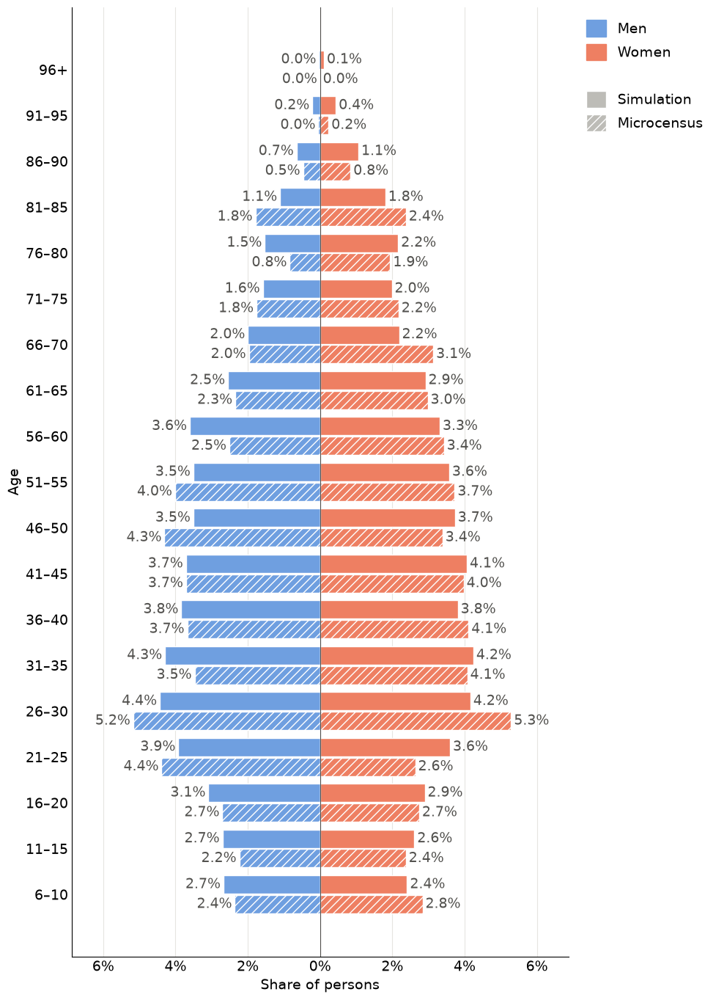

         sim            mz        diff_pp       
sex_    male female   male female    male female
6–10   2.674  2.408  2.358  2.836   0.316 -0.428
11–15  2.701  2.609  2.235  2.374   0.466  0.235
16–20  3.089  2.896  2.704  2.742   0.385  0.154
21–25  3.922  3.595  4.385  2.634  -0.464  0.962
26–30  4.434  4.160  5.170  5.286  -0.736 -1.126
31–35  4.291  4.242  3.472  4.074   0.819  0.168
36–40  3.839  3.812  3.675  4.108   0.164 -0.296
41–45  3.711  4.062  3.708  3.974   0.003  0.088
46–50  3.507  3.733  4.305  3.388  -0.798  0.345
51–55  3.507  3.574  4.012  3.725  -0.505 -0.151
56–60  3.604  3.311  2.511  3.426   1.094 -0.115
61–65  2.548  2.918  2.346  2.978   0.203 -0.061
66–70  1.996  2.188  1.971  3.133   0.025 -0.944
71–75  1.584  1.984  1.759  2.172  -0.175 -0.188
76–80  1.529  2.161  0.839  1.941   0.690  0.220
81–85  1.108  1.807  1.789  2.375  -0.681 -0.568
86–90  0.650  1.062  0.471  0.843   0.179  0.219
91–95  0.214  0.436  0.048  0.234   0.166  0.202
96+    0.027  0.107 

In [13]:
def pyramid_shares(df):
    t = df.pivot_table(index='age_group', columns='sex_', values='weight', aggfunc='sum',
                       fill_value=0, observed=False).reindex(columns=['male', 'female'], fill_value=0)
    return t / t.to_numpy().sum()


def plot_pyramid(sim, mz, fname):
    s, m = pyramid_shares(sim) * 100, pyramid_shares(mz) * 100
    labels = [nice_label(i) for i in s.index]
    y = np.arange(len(labels))                        # youngest group at the bottom
    h, gap = 0.4, 0.03
    pad = max(s.to_numpy().max(), m.to_numpy().max()) * 0.015
    fig, ax = plt.subplots(figsize=(10, 0.65 * len(labels) + 1.5))
    for offset, data, hatch in [(+(h + gap) / 2, s, None), (-(h + gap) / 2, m, HATCH_MZ)]:
        for sex, sign in [('male', -1), ('female', 1)]:          # men left, women right
            ax.barh(y + offset, sign * data[sex], h, color=SEX_COLORS[sex], hatch=hatch,
                    edgecolor='white', linewidth=1.0)
            for yi, v in zip(y + offset, data[sex]):
                ax.text(sign * (v + pad), yi, f'{v:.1f}%', va='center', ha='left' if sign > 0 else 'right',
                        fontsize=FS['value'], color=TEXT_COLOR)
    ax.axvline(0, color=TEXT_COLOR, linewidth=0.8)
    ax.set_yticks(y, labels)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.0f}%'))
    xmax = max(s.to_numpy().max(), m.to_numpy().max()) * 1.3          # room for the labels
    ax.set_xlim(-xmax, xmax)
    ax.set_xlabel('Share of persons')
    ax.set_ylabel('Age')
    style_axes(ax, 'x')
    handles = [Patch(color=SEX_COLORS['male'], label='Men'), Patch(color=SEX_COLORS['female'], label='Women'),
               Patch(color='none', label='')] + src_legend()
    ax.legend(handles=handles, frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left',
              handlelength=1.4, handleheight=1.4)
    finish(fig, fname)


plot_pyramid(sim_p, mz_p, 'age_pyramid.png')
ps, pm = pyramid_shares(sim_p) * 100, pyramid_shares(mz_p) * 100
pyramid = pd.concat({'sim': ps, 'mz': pm, 'diff_pp': ps - pm}, axis=1).round(3)
pyramid.index = [nice_label(i) for i in pyramid.index]
save_table(pyramid, 'age_pyramid_table.csv')


           sim      mz  diff_pp  n_sim  n_mz
sex                                         
male    0.4893  0.4776   1.1783  16034   891
female  0.5107  0.5224  -1.1783  16732  1052


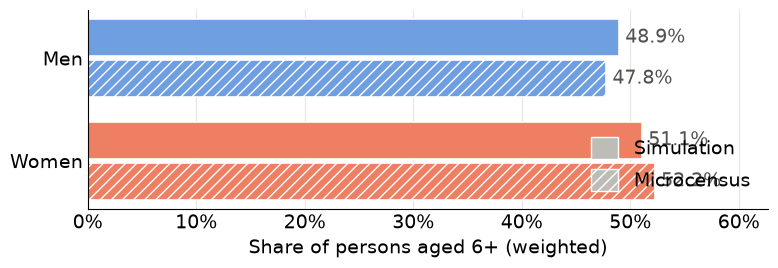

In [14]:
SEX_CATS = ['male', 'female']
sex_cmp = compare(sim_p, mz_p, 'sex_', SEX_CATS)
sex_cmp.index.name = 'sex'
save_table(sex_cmp, 'sex_share_table.csv')
plot_hbars(sim_p, mz_p, 'sex_', SEX_CATS, 'sex_share.png', labels=dict(male='Men', female='Women'),
           colors=SEX_COLORS, xlabel=f'Share of persons aged {MIN_AGE}+ (weighted)')


        sim      mz  diff_pp  n_sim  n_mz
age                                      
6    0.0101  0.0055   0.4664    332    11
7    0.0101  0.0093   0.0768    330    23
8    0.0107  0.0123  -0.1613    350    24
9    0.0098  0.0119  -0.2030    322    28
10   0.0101  0.0130  -0.2907    331    30
11   0.0103  0.0113  -0.0968    337    26
12   0.0112  0.0079   0.3365    368    20
13   0.0104  0.0100   0.0432    342    25
14   0.0103  0.0089   0.1409    337    25
15   0.0109  0.0081   0.2778    356    24


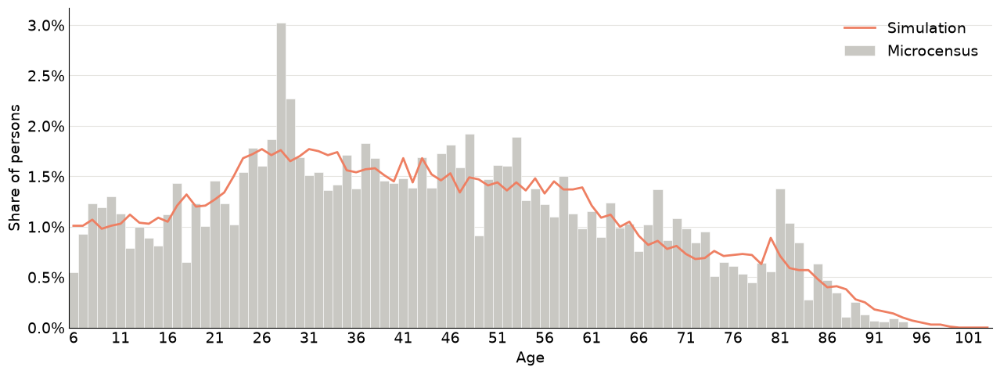

In [15]:
ages = list(range(MIN_AGE, int(max(sim_p['age_1y'].max(), mz_p['age_1y'].max())) + 1))
age_cmp = compare(sim_p, mz_p, 'age_1y', ages)
age_cmp.index.name = 'age'
save_table(age_cmp.head(10), 'age_distribution_1y_table.csv', show=True)
age_cmp.to_csv(OUT_DIR / 'age_distribution_1y_table.csv')      # full table (the line above only prints the head)

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(ages, age_cmp['mz'], width=1.0, color=COLORS['outside'], edgecolor='white', linewidth=0.4, label='Microcensus')
ax.plot(ages, age_cmp['sim'], color=COLORS['car'], linewidth=2, label='Simulation')
ax.set_xlim(ages[0] - 0.5, ages[-1] + 0.5)
ax.set_xticks(range(ages[0], ages[-1] + 1, 5))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.set_xlabel('Age')
ax.set_ylabel('Share of persons')
style_axes(ax, 'y')
ax.legend(frameon=False)
finish(fig, 'age_distribution_1y.png')


            sim      mz  diff_pp  n_sim  n_mz
licence                                      
yes      0.7035  0.6793   2.4283  23052  1313
no       0.2965  0.3207  -2.4283   9714   630


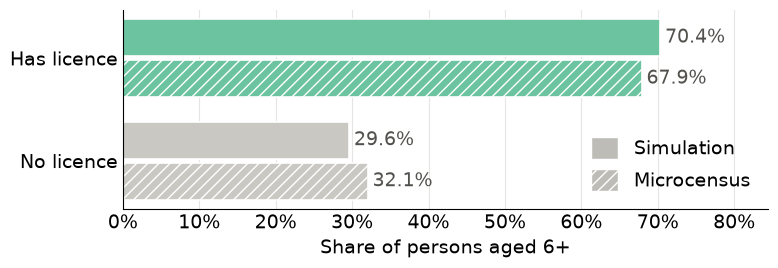

In [16]:
LICENCE = ['yes', 'no']
licence_cmp = compare(sim_p, mz_p, 'licence', LICENCE)
save_table(licence_cmp, 'driving_licence_table.csv')
plot_hbars(sim_p, mz_p, 'licence', LICENCE, 'driving_licence.png',
           labels=dict(yes='Has licence', no='No licence'), colors=LICENCE_COLORS,
           xlabel=f'Share of persons aged {MIN_AGE}+')


           sim_holders_weighted  sim_holders_n  sim_group_total_weighted  \
age_group                                                                  
6–17                        0.0              0                    4144.0   
18–24                    1918.0           1918                    3120.0   
25–64                   16959.0          16959                   19635.0   
65–79                    3041.0           3041                    3803.0   
80+                      1134.0           1134                    2064.0   

           sim_rate_in_group  sim_share_of_holders  mz_holders_weighted  \
age_group                                                                 
6–17                   0.000                 0.000                0.000   
18–24                  0.615                 0.083              104.335   
25–64                  0.864                 0.736             1113.041   
65–79                  0.800                 0.132              196.162   
80+              

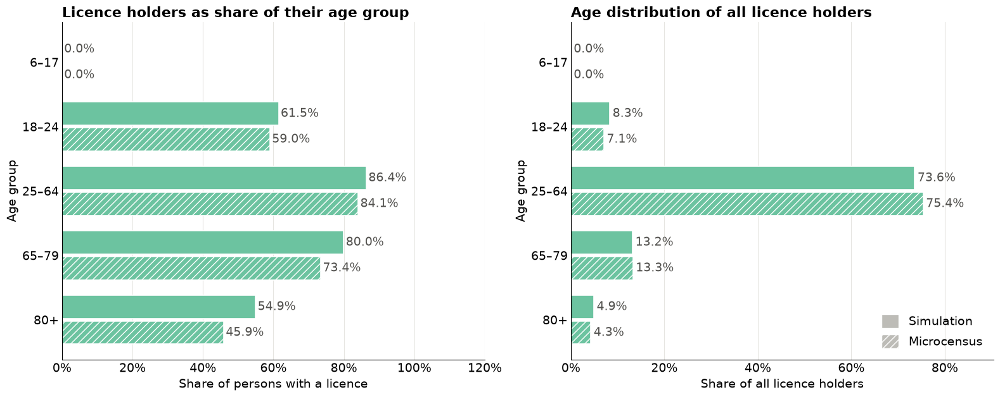

In [17]:
LIC_BINS   = [MIN_AGE, 18, 25, 65, 80, 120]
LIC_LABELS = [f'{MIN_AGE}–17', '18–24', '25–64', '65–79', '80+']


def licence_by_age(df):
    """Per age group: licence holders (weighted + raw), share of the group holding a licence,
    and share of all holders falling in the group."""
    d = df[df['licence'].notna()].copy()
    d['lic_age'] = pd.cut(d['age'], LIC_BINS, right=False, labels=LIC_LABELS)
    total = d.groupby('lic_age', observed=False)['weight'].sum()
    yes = d[d['licence'] == 'yes']
    out = pd.DataFrame({'holders_weighted': yes.groupby('lic_age', observed=False)['weight'].sum(),
                        'holders_n': yes.groupby('lic_age', observed=False).size(),
                        'group_total_weighted': total})
    out['rate_in_group']    = out['holders_weighted'] / out['group_total_weighted']
    out['share_of_holders'] = out['holders_weighted'] / out['holders_weighted'].sum()
    return out.fillna(0)


lic_sim, lic_mz = licence_by_age(sim_p), licence_by_age(mz_p)
lic_cmp = lic_sim.add_prefix('sim_').join(lic_mz.add_prefix('mz_'))
lic_cmp['diff_rate_pp']  = (lic_cmp['sim_rate_in_group'] - lic_cmp['mz_rate_in_group']) * 100
lic_cmp['diff_share_pp'] = (lic_cmp['sim_share_of_holders'] - lic_cmp['mz_share_of_holders']) * 100
lic_cmp.index.name = 'age_group'
save_table(lic_cmp.round(3), 'driving_licence_by_age_table.csv')

fig, axes = plt.subplots(1, 2, figsize=(16, 0.9 * len(LIC_LABELS) + 2))
colors = {c: LICENCE_COLORS['yes'] for c in LIC_LABELS}
for ax, col, title, xlabel in [
        (axes[0], 'rate_in_group', 'Licence holders as share of their age group', 'Share of persons with a licence'),
        (axes[1], 'share_of_holders', 'Age distribution of all licence holders', 'Share of all licence holders')]:
    draw_hbars(ax, lic_sim[col], lic_mz[col], LIC_LABELS, {c: c for c in LIC_LABELS}, colors)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Age group')
axes[0].set_xlim(0, 1.2)
axes[1].legend(handles=src_legend(), frameon=False, loc='lower right', handlelength=1.4, handleheight=1.4)
finish(fig, 'driving_licence_by_age.png')


             sim      mz  diff_pp  n_sim  n_mz
cat                                           
urban     0.9238  0.7399  18.3844  14768  1348
suburban  0.0762  0.2220 -14.5773   1219   489
rural     0.0000  0.0381  -3.8072      0   106


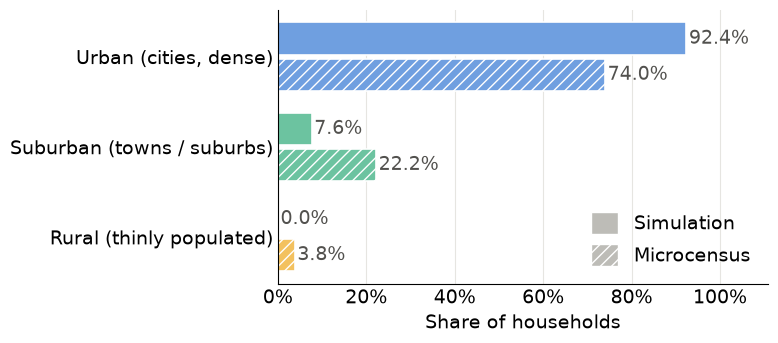

In [18]:
present = set(sim_hh['cat']) | set(mz_hh['cat'])
hh_cats = [c for c in HH_CATS if c in present]
hh_cmp = compare(sim_hh, mz_hh, 'cat', hh_cats)
save_table(hh_cmp, 'household_urbanity_table.csv')
plot_hbars(sim_hh, mz_hh, 'cat', hh_cats, 'household_urbanity.png',
           labels=dict(urban='Urban (cities, dense)', suburban='Suburban (towns / suburbs)',
                       rural='Rural (thinly populated)', unknown='Unknown / missing'),
           colors=URBAN_COLORS, xlabel='Share of households')


 ## Home municipality

 Simulation (home activity), Microcensus (home coordinates) and canton Vaud statistics for the

 municipalities that touch the study area. Shares are relative to the sum over these municipalities.

In [19]:
munis_all = gpd.read_file(MUNI_FILE)
munis_all = munis_all.set_crs(2056) if munis_all.crs is None else munis_all.to_crs(2056)
print('shapefile columns:', [c for c in munis_all.columns if c != 'geometry'])

# column holding the municipality name (set NAME_COL by hand if the guess is wrong)
NAME_COL = next((c for pref in ('nom_min', 'nom_maj', 'nom', 'name', 'commune', 'nom_commune', 'gemeindename')
                 for c in munis_all.columns if c.lower() == pref), None)
if NAME_COL is None:
    NAME_COL = next(c for c in munis_all.columns
                    if c != 'geometry' and munis_all[c].dtype == object and munis_all[c].notna().any())
print('municipality name column:', NAME_COL)


def norm_name(s):
    """Comparable municipality name: no accents / case / punctuation / suffix like '(VD)'."""
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'[^a-z0-9]+', ' ', re.sub(r'\(.*?\)', '', s)).strip()


def read_canton_population(path, sheet):
    """One row per municipality (bfs, name, resident population); rows with an integer BFS number in column B."""
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    rows = []
    for _, r in raw.iterrows():
        bfs = pd.to_numeric(r[1], errors='coerce')
        if pd.notna(bfs) and isinstance(r[2], str) and pd.notna(r[5]):
            rows.append((int(bfs), r[2].strip(), float(r[5])))
    return pd.DataFrame(rows, columns=['bfs', 'name', 'pop'])


canton = read_canton_population(CANTON_FILE, CANTON_SHEET)
print(f'Canton data: {len(canton)} municipalities, total {canton["pop"].sum():,.0f} residents')

# municipalities in the study area
overlap = munis_all.geometry.intersection(shape).area / munis_all.geometry.area
in_area = munis_all[(overlap > 0) & (overlap >= MIN_OVERLAP)].copy()

# link shapefile -> Excel by BFS number (if a shapefile column holds them), otherwise by name
bfs_col = next((c for c in munis_all.columns if c != 'geometry'
                and pd.to_numeric(munis_all[c], errors='coerce').isin(canton['bfs']).mean() > 0.5), None)
if bfs_col:
    in_area['canton_pop'] = pd.to_numeric(in_area[bfs_col], errors='coerce').map(canton.set_index('bfs')['pop'])
    print(f'Municipalities linked to the Excel by BFS number (column {bfs_col})')
else:
    by_name = canton.assign(k=canton['name'].map(norm_name)).set_index('k')['pop']
    in_area['canton_pop'] = in_area[NAME_COL].map(norm_name).map(by_name)
    print(f'Municipalities linked to the Excel by name (column {NAME_COL})')
if in_area['canton_pop'].isna().any():
    print('WARNING: no canton figure for', in_area.loc[in_area['canton_pop'].isna(), NAME_COL].tolist())
in_area = in_area.dropna(subset=['canton_pop'])
canton_pop   = in_area.groupby(NAME_COL)['canton_pop'].sum()
canton_share = canton_pop / canton_pop.sum()
print(f'{len(in_area)} municipalities in the study area, {canton_pop.sum():,.0f} residents (canton statistics)')


def muni_of(x, y):
    """Name of the municipality containing each point (NaN if none / missing coordinates)."""
    pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(np.asarray(x, float), np.asarray(y, float)), crs=2056)
    j = gpd.sjoin(pts, munis_all[[NAME_COL, 'geometry']], how='left', predicate='within')
    j = j[~j.index.duplicated()]
    return j[NAME_COL].reindex(pts.index).to_numpy()



shapefile columns: ['fme_featur', 'NO_COM_CAN', 'NO_COM_FED', 'NOM_MIN', 'NOM_MAJ', 'NO_DIS_CAN', 'NO_DIS_FED', 'NO_CANTON', 'SHAPE_AREA', 'SHAPE_LEN', 'ID_DWH', 'OBJECTID', 'fme_geomet', 'fme_type', 'geodb_oid', 'geodb_type']
municipality name column: NOM_MIN
Canton data: 300 municipalities, total 864,226 residents
Municipalities linked to the Excel by BFS number (column NO_COM_FED)
39 municipalities in the study area, 366,231 residents (canton statistics)


Simulation: 0 persons without a 'home' activity
MZ: 0 persons without home coordinates
                          sim      mz  diff_pp  n_sim  n_mz  canton
municipality                                                       
Lausanne               0.4080  0.3924   1.5560  13367   718  0.3979
Renens (VD)            0.0639  0.0647  -0.0783   2095   120  0.0596
Pully                  0.0568  0.0598  -0.3008   1860   125  0.0534
Morges                 0.0521  0.0545  -0.2388   1706   100  0.0486
Prilly                 0.0370  0.0473  -1.0294   1212    83  0.0357
Ecublens (VD)          0.0368  0.0402  -0.3417   1205    76  0.0376
Bussigny               0.0312  0.0334  -0.2177   1023    66  0.0331
Lutry                  0.0315  0.0266   0.4875   1031    58  0.0296
Epalinges              0.0302  0.0300   0.0144    989    63  0.0269
Crissier               0.0267  0.0249   0.1805    876    45  0.0304
Le Mont-sur-Lausanne   0.0274  0.0261   0.1258    897    58  0.0267
Chavannes-près-Renens  0.0255

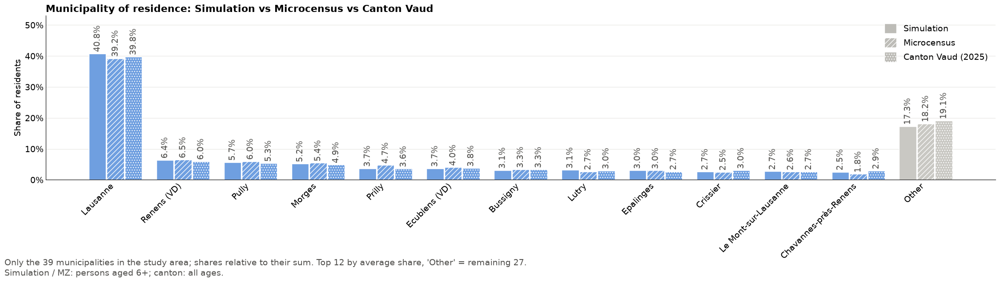

In [20]:
# simulation: coordinates of the first 'home' activity of every person
home_act = (sim_acts[sim_acts['type'] == 'home'].dropna(subset=['x', 'y'])
            .drop_duplicates('person')[['person', 'x', 'y']])
sim_home = sim_p[['person', 'weight']].merge(home_act, on='person', how='left')
print(f"Simulation: {sim_home['x'].isna().sum():,} persons without a 'home' activity")
sim_home['muni'] = muni_of(sim_home['x'], sim_home['y'])

# Microcensus: home coordinates of the household
mz_home = mz_p[['HHNR', 'weight']].merge(mz_hh[['HHNR', 'x', 'y']], on='HHNR', how='left')
print(f"MZ: {mz_home['x'].isna().sum():,} persons without home coordinates")
mz_home['muni'] = muni_of(mz_home['x'], mz_home['y'])

# keep persons living in one of the study-area municipalities; shares are relative to those
sim_home = sim_home[sim_home['muni'].isin(canton_pop.index)]
mz_home  = mz_home[mz_home['muni'].isin(canton_pop.index)]
if sim_home.empty or mz_home.empty:
    raise ValueError(f'No home matched a municipality - check NAME_COL ({NAME_COL}) and the shapefile CRS.')

# full table (all municipalities, sorted by average share), then top N + 'Other'
all_munis = sorted(set(sim_home['muni']) | set(mz_home['muni']) | set(canton_share.index))
sim_sh, mz_sh = shares(sim_home, 'muni', all_munis), shares(mz_home, 'muni', all_munis)
can_sh = canton_share.reindex(all_munis).fillna(0)
all_munis = list(((sim_sh + mz_sh + can_sh) / 3).sort_values(ascending=False).index)

home_full = compare(sim_home, mz_home, 'muni', all_munis)
home_full['canton']             = can_sh.reindex(all_munis).round(4)
home_full['diff_sim_canton_pp'] = ((home_full['sim'] - home_full['canton']) * 100).round(4)
home_full['diff_mz_canton_pp']  = ((home_full['mz'] - home_full['canton']) * 100).round(4)
home_full['canton_pop']         = canton_pop.reindex(all_munis)
home_full.index.name = 'municipality'
home_full.to_csv(OUT_DIR / 'home_municipality_table.csv')

top_m = all_munis[:TOP_MUNIS]
muni_cats = top_m + (['Other'] if len(all_munis) > TOP_MUNIS else [])
group = lambda df: df.assign(muni=df['muni'].where(df['muni'].isin(top_m), 'Other'))
sim_g, mz_g = group(sim_home), group(mz_home)
can_g = can_sh.groupby(can_sh.index.where(can_sh.index.isin(top_m), 'Other')).sum()
home_cmp = compare(sim_g, mz_g, 'muni', muni_cats)
home_cmp['canton'] = can_g.reindex(muni_cats).round(4)
home_cmp.index.name = 'municipality'
save_table(home_cmp, 'home_municipality_table_top.csv')

grouped_bars(sim_vs_mz(shares(sim_g, 'muni', muni_cats), shares(mz_g, 'muni', muni_cats))
             + [(f'Canton Vaud ({CANTON_SHEET})', can_g, HATCH_CAN)],
             muni_cats, 'home_municipality.png', labels={c: c for c in muni_cats},
             colors={**{c: COLORS['pt'] for c in top_m}, 'Other': COLORS['outside']},
             ylabel='Share of residents', rotate=45,
             title='Municipality of residence: Simulation vs Microcensus vs Canton Vaud',
             note=f"Only the {len(canton_pop)} municipalities in the study area; shares relative to their sum.\n"
                  f"Top {TOP_MUNIS} by average share, 'Other' = remaining {max(len(all_munis) - TOP_MUNIS, 0)}. "
                  f"Simulation / MZ: persons aged {MIN_AGE}+; canton: all ages.",
             note_y=-0.1) if False else None   # (see next line: note_y is not a grouped_bars argument)
grouped_bars(sim_vs_mz(shares(sim_g, 'muni', muni_cats), shares(mz_g, 'muni', muni_cats))
             + [(f'Canton Vaud ({CANTON_SHEET})', can_g, HATCH_CAN)],
             muni_cats, 'home_municipality.png', labels={c: c for c in muni_cats},
             colors={**{c: COLORS['pt'] for c in top_m}, 'Other': COLORS['outside']},
             ylabel='Share of residents', rotate=45,
             title='Municipality of residence: Simulation vs Microcensus vs Canton Vaud',
             note=f"Only the {len(canton_pop)} municipalities in the study area; shares relative to their sum. "
                  f"Top {TOP_MUNIS} by average share, 'Other' = remaining {max(len(all_munis) - TOP_MUNIS, 0)}.\n"
                  f"Simulation / MZ: persons aged {MIN_AGE}+; canton: all ages.")


 ## Public-transport quality (ÖV-Güteklasse)

 Bars: simulation household attribute `ovgk`, MZ `W_OeV_KLASSE` (weighted with `WM`), and the ARE class

 (geo.admin.ch, layer `ch.are.gueteklassen_oev`) looked up at the home coordinates of the simulation and of the

 Microcensus households. Lookups are cached in `results/are_gueteklasse_lookup.csv` (internet needed on the first run).

In [21]:
ARE_IDENTIFY_URL = 'https://api3.geo.admin.ch/rest/services/api/MapServer/identify'
ARE_LAYER        = 'ch.are.gueteklassen_oev'
ARE_CACHE        = OUT_DIR / 'are_gueteklasse_lookup.csv'
ARE_CLASS_FIELD  = None      # attribute holding the class; None = auto-detect


def are_class_from_attrs(attrs):
    """Class letter from the attributes of one identified polygon (e.g. 'D - geringe Erschliessung' -> 'D')."""
    keys = [ARE_CLASS_FIELD] if ARE_CLASS_FIELD else [k for k in attrs if 'klass' in k.lower() or 'class' in k.lower()]
    for k in keys + list(attrs):
        v = str(attrs.get(k, '')).strip().upper()
        if v[:1] in 'ABCDEF' and v[:1] and (len(v) == 1 or v[1:2] in (' ', '-')):
            return v[0]
    return None


def are_class_at(x, y, retries=3):
    """ARE class at an LV95 point: 'A'-'D', 'none' (no polygon = marginal / no PT service) or 'error'."""
    params = {'geometryType': 'esriGeometryPoint', 'geometry': f'{x},{y}', 'sr': 2056, 'layers': f'all:{ARE_LAYER}',
              'tolerance': 0, 'mapExtent': f'{x - 50},{y - 50},{x + 50},{y + 50}', 'imageDisplay': '100,100,96',
              'returnGeometry': 'false', 'lang': 'en'}
    url = ARE_IDENTIFY_URL + '?' + urllib.parse.urlencode(params)
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, timeout=20) as r:
                results = json.load(r).get('results', [])
            break
        except Exception:
            if attempt == retries - 1:
                return 'error'
    if not results:
        return 'none'
    found = [c for c in (are_class_from_attrs(r.get('attributes', {})) for r in results) if c]
    if not found:
        return 'error'                    # polygon without a recognised class field -> set ARE_CLASS_FIELD
    best = min(found)                     # overlapping polygons: keep the best class
    return best if best in 'ABCD' else 'none'


def lookup_are_classes(xy):
    """Class for every unique (rounded) LV95 coordinate in `xy` (columns x, y); cached on disk."""
    cache = pd.read_csv(ARE_CACHE) if ARE_CACHE.exists() else pd.DataFrame({'x': [], 'y': [], 'cls': []})
    cache = cache[cache['cls'] != 'error'].astype({'x': float, 'y': float})
    todo = (xy.merge(cache[['x', 'y']], how='left', indicator=True)
              .query("_merge == 'left_only'")[['x', 'y']])
    if len(todo):
        print(f'Querying the ARE service for {len(todo):,} coordinates ...')
        with ThreadPoolExecutor(max_workers=8) as ex:
            cls = list(ex.map(are_class_at, todo['x'].astype(int), todo['y'].astype(int)))
        cache = pd.concat([cache, todo.assign(cls=cls)]).drop_duplicates(['x', 'y'], keep='last')
        cache.to_csv(ARE_CACHE, index=False)
    return cache


def add_are_class(df):
    """df with columns x, y (LV95, may be NaN) -> adds 'cat' = ARE class or 'unknown'."""
    df = df.assign(x=df['x'].round(0), y=df['y'].round(0))
    cache = lookup_are_classes(df[['x', 'y']].dropna().drop_duplicates())
    df = df.merge(cache, on=['x', 'y'], how='left')
    df['cat'] = df['cls'].fillna('unknown').replace('error', 'unknown')
    return df


# simulation: household attribute 'ovgk' (missing attribute -> unknown, anything else than A-D -> none)
print('Simulation ovgk, raw values:'); print(sim_hh['ovgk'].fillna('<missing>').value_counts().to_string())
sim_ov = sim_hh[['id', 'weight']].assign(
    cat=sim_hh['ovgk'].str.upper().map(lambda v: v if v in ('A', 'B', 'C', 'D') else 'none'))
sim_ov.loc[sim_hh['ovgk'].isna(), 'cat'] = 'unknown'
mz_ov = mz_hh.rename(columns={'ov': 'cat'})[['HHNR', 'weight', 'cat']]

# simulation addresses: one home coordinate per household (first member that has one)
sim_hh_xy = (sim_members.merge(sim_all[['person', 'home_x', 'home_y']], on='person')
             .dropna(subset=['home_x', 'home_y']).drop_duplicates('hh')
             .rename(columns={'hh': 'id', 'home_x': 'x', 'home_y': 'y'})[['id', 'x', 'y']])
print(f"Simulation: {len(sim_hh_xy):,} of {len(sim_hh):,} households have a home coordinate")
sim_addr = add_are_class(sim_hh[['id', 'weight']].merge(sim_hh_xy, on='id', how='left'))

# Microcensus addresses
mz_addr = add_are_class(mz_hh[['HHNR', 'weight', 'x', 'y']])
print('ARE class counts, simulation addresses:'); print(sim_addr['cat'].value_counts().to_string())
print('ARE class counts, MZ addresses:');         print(mz_addr['cat'].value_counts().to_string())

ov_cats = OV_CATS + (['unknown'] if any('unknown' in set(d['cat']) for d in (sim_ov, mz_ov, sim_addr, mz_addr)) else [])
ov_cmp = compare(sim_ov, mz_ov, 'cat', ov_cats)
ov_cmp['sim_addr'] = shares(sim_addr, 'cat', ov_cats).round(4)
ov_cmp['mz_addr']  = shares(mz_addr, 'cat', ov_cats).round(4)
ov_cmp['diff_sim_vs_sim_addr_pp'] = ((ov_cmp['sim'] - ov_cmp['sim_addr']) * 100).round(4)
ov_cmp['diff_sim_vs_mz_addr_pp']  = ((ov_cmp['sim'] - ov_cmp['mz_addr']) * 100).round(4)
ov_cmp.index.name = 'oev_class'
save_table(ov_cmp, 'oev_gueteklasse_table.csv')

grouped_bars([('Simulation', shares(sim_ov, 'cat', ov_cats), None),
              ('Microcensus (W_OeV_KLASSE)', shares(mz_ov, 'cat', ov_cats), HATCH_MZ),
              ('Simulation addresses (ARE map)', shares(sim_addr, 'cat', ov_cats), '.'),
              ('Microcensus addresses (ARE map)', shares(mz_addr, 'cat', ov_cats), '++')],
             ov_cats, 'oev_gueteklasse.png', labels=OV_LABELS, colors=OV_COLORS, ylabel='Share of households',
             title='Public-transport quality: Simulation vs Microcensus vs ARE at addresses',
             note='Dotted / grid bars: ARE Güteklasse (geo.admin.ch) at the household home coordinates of the '
                  'simulation and of the Microcensus (weighted with WM).')


Simulation ovgk, raw values:
ovgk
A       12140
B        2420
C         839
D         353
None      235
Simulation: 15,987 of 15,987 households have a home coordinate
ARE class counts, simulation addresses:
cat
A       7185
B       5442
C       2253
D        782
none     325
ARE class counts, MZ addresses:
cat
A       734
B       697
C       330
D       121
none     61


ValueError: Grouper for 'cat' not 1-dimensional

 ## Income

Simulation: incomeClass read from households; 15,987 of 15,987 have a value
MZ: 1,943 households; raw income codes (negative = missing):
income
-99    295
-98    118
-97    151
 1      40
 2     169
 3     260
 4     265
 5     218
 6     144
 7      86
 8      72
 9     125
                 sim      mz  diff_pp  n_sim  n_mz
income_class                                      
1             0.0422  0.0430  -0.0827    674    40
2             0.1842  0.1651   1.9065   2945   169
3             0.2216  0.2368  -1.5187   3543   260
4             0.1653  0.1920  -2.6721   2643   265
5             0.1260  0.1307  -0.4690   2015   218
6             0.0864  0.0836   0.2844   1382   144
7             0.0480  0.0459   0.2148    768    86
8             0.0415  0.0427  -0.1176    664    72
9             0.0846  0.0601   2.4544   1353   125


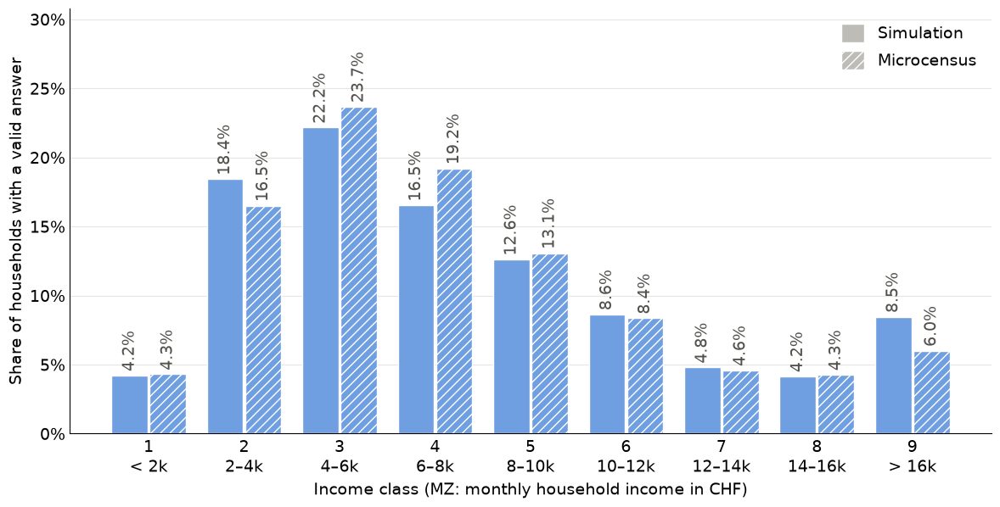

In [22]:
# Simulation: incomeClass on the household if present, otherwise on the person (classes 0-8 -> +1 = MZ 1-9)
sim_hh['income'] = pd.to_numeric(sim_hh['incomeClass'], errors='coerce') + 1
if sim_hh['income'].notna().any():
    unit = 'households'
    sim_inc = sim_hh[['id', 'income', 'weight']]
    # income of every person = income of its household (used for the chain comparison)
    sim_p['income'] = (sim_p['person'].map(sim_members.set_index('person')['hh'])
                       .map(sim_hh.set_index('id')['income']))
else:
    unit = 'persons'
    sim_p['income'] = sim_p['incomeClass'] + 1
    sim_inc = sim_p[['person', 'income', 'weight']]
print(f'Simulation: incomeClass read from {unit}; {sim_inc["income"].notna().sum():,} of {len(sim_inc):,} have a value')

print(f'MZ: {len(mz_hh):,} households; raw income codes (negative = missing):')
print(mz_hh['income'].value_counts().sort_index().to_string())

# valid answers only; shares are relative to valid answers
sim_inc = sim_inc[sim_inc['income'].notna()].astype({'income': int})
mz_inc  = mz_hh[mz_hh['income'] >= 1].astype({'income': int})

INCOME_CATS = sorted(set(MZ_INCOME_LABELS) | set(sim_inc['income']) | set(mz_inc['income']))
income_cmp = compare(sim_inc, mz_inc, 'income', INCOME_CATS)
income_cmp.index.name = 'income_class'
save_table(income_cmp, 'income_distribution_table.csv')

grouped_bars(sim_vs_mz(income_cmp['sim'], income_cmp['mz']), INCOME_CATS, 'income_distribution.png',
             labels={c: f'{c}\n{MZ_INCOME_LABELS.get(c, "")}' for c in INCOME_CATS},
             colors={c: COLORS['pt'] for c in INCOME_CATS},
             xlabel='Income class (MZ: monthly household income in CHF)',
             ylabel=f'Share of {unit} with a valid answer')


 ## Activity chains

 Home-based tours as letter strings, e.g. `HWH` = home – work – home. Persons without any tour count as `H`.

 Only the `TOP_N_CHAINS` most frequent chains are shown individually, the others are grouped in `Other`.

 MZ purpose codes (`wzweck1`): 1 change of mode, 2 work, 3 education, 4 shopping, 5 errands, 6 business,

 7 service trip, 8 leisure, 9 accompanying (children), 10 accompanying (others), 11 return home, 12 other, 13 border crossing.

In [23]:
def merge_outside(chain):
    """Collapse consecutive 'Ou' stops: HOuOuH -> HOuH."""
    return re.sub(r'(?:Ou)+', 'Ou', chain)


def split_into_tours(codes):
    """Cut a letter sequence at every 'H' into complete home-to-home tours (the parts before the first
    and after the last H are discarded): ['H','W','H','S','L','H'] -> ['HWH', 'HSLH']"""
    tours, current, started = [], [], False
    for code in codes:
        if code == 'H':
            if started and current:
                tours.append('H' + ''.join(current) + 'H')
            current, started = [], True
        elif started:
            current.append(code)
    return tours


def plan_tours(seq, mode):
    """One daily letter sequence -> (tours, status). Status: 'home' (never leaves home), 'excluded'
    (no usable tour), 'ok', or 'closed' (plan repaired according to `mode`)."""
    if all(c == 'H' for c in seq):
        return [], 'home'
    if 'H' not in seq:
        return [], 'excluded'
    if seq[0] == 'H' and seq[-1] == 'H':
        return split_into_tours(seq), 'ok'
    if mode == 'drop':                              # throw away the incomplete beginning / end
        tours = split_into_tours(seq)
        return tours, ('ok' if tours else 'excluded')
    if mode == 'cyclic':                            # rotate the plan so that it starts at the first home
        first = seq.index('H')
        seq = seq[first:] + seq[:first] + ['H']
    else:                                           # 'insert': add the missing home at the start / end
        seq = (['H'] if seq[0] != 'H' else []) + seq + (['H'] if seq[-1] != 'H' else [])
    return split_into_tours(seq), 'closed'


def to_letters(purposes, outside_flags):
    """MZ purpose codes -> chain letters. Home trips and unknown codes are dropped, trips ending outside -> 'Ou'."""
    letters = []
    for code, outside in zip(purposes, outside_flags):
        if code == MZ_HOME:
            continue
        letter = 'Ou' if outside else MZ_MAP.get(code)
        if letter:
            letters.append(letter)
    return letters


def person_tours(trips):
    """Tour strings of one MZ person from its ordered trips."""
    if USE_OUTINGS and 'ausnr' in trips.columns:    # one tour per outing; the last trip leads back home
        tours = []
        for _, outing in trips.groupby('ausnr', sort=False):
            acts = to_letters(outing['wzweck1'].iloc[:-1], outing['outside'].iloc[:-1])
            if acts:
                tours.append(merge_outside('H' + ''.join(acts) + 'H'))
        return tours
    pairs = list(zip(trips['wzweck1'], trips['outside']))
    if COLLAPSE_RETURN_PAIRS:                       # one tour per day, consecutive duplicates merged
        kept = [p for i, p in enumerate(pairs) if i == 0 or p[0] != pairs[i - 1][0]]
        acts = to_letters(*zip(*kept)) if kept else []
        return [merge_outside('H' + ''.join(acts) + 'H')] if acts else []
    seq = ['H']                                     # split the day at every explicit home trip
    for code, out in pairs:
        seq += ['H'] if code == MZ_HOME else to_letters([code], [out])
    return [merge_outside(t) for t in split_into_tours(seq)]


def chain_order(sim, mz):
    """All chains, most frequent in the MZ first."""
    rank = mz.groupby('chain')['weight'].sum().sort_values(ascending=False)
    return list(rank.index) + [c for c in sim['chain'].unique() if c not in rank.index]


def group_other(df, top):
    """Copy of df where every chain outside `top` is renamed 'Other'."""
    return df.assign(chain=df['chain'].where(df['chain'].isin(top), OTHER))



In [24]:
# simulation: letter sequence per person from the selected plan
seqs = (sim_acts.assign(letter=sim_acts['type'].map(MATSIM_MAP)).dropna(subset=['letter'])
        .groupby('person', sort=False)['letter'].agg(list))
rows, status = [], Counter()
for pid, has_leg in zip(sim_p['person'], sim_p['has_leg']):
    tours, st = plan_tours(seqs.get(pid, []), CLOSE_MODE) if has_leg else ([], 'home')
    status[st] += 1
    if tours:
        rows += [(pid, merge_outside(t)) for t in tours]
    elif st == 'home':
        rows.append((pid, 'H'))                     # 'excluded' persons are not counted
sim_chains = (pd.DataFrame(rows, columns=['person', 'chain'])
              .merge(sim_p[['person', 'sex_', 'licence', 'age', 'income']], on='person'))
sim_chains['weight'] = 1.0
print('Simulation plan status:', dict(status))

# Microcensus: tours of the weekday persons, weighted with the person weight
rows = [(hh, t) for hh, g in mz_t.groupby('HHNR') for t in person_tours(g)]
mz_chains = pd.DataFrame(rows, columns=['HHNR', 'chain']).merge(
    mz_pw[['HHNR', 'sex_', 'licence', 'age', 'weight']], on='HHNR')
stay = mz_pw[~mz_pw['HHNR'].isin(mz_chains['HHNR'])][['HHNR', 'sex_', 'licence', 'age', 'weight']].assign(chain='H')
mz_chains = pd.concat([mz_chains, stay], ignore_index=True)
mz_chains = mz_chains.merge(mz_hh[['HHNR', 'income']], on='HHNR', how='left')       # household income
print(f'MZ: {len(stay):,} weekday persons without any tour (counted as H)')
print(f'Tours (unweighted): simulation {len(sim_chains):,}, MZ {len(mz_chains):,}')
print(f"Simulation: {sim_chains['income'].notna().mean():.1%} of the tours have an income class")


Simulation plan status: {'ok': 27528, 'excluded': 1588, 'home': 3650}
MZ: 124 weekday persons without any tour (counted as H)
Tours (unweighted): simulation 46,877, MZ 2,003
Simulation: 100.0% of the tours have an income class


        simulation  microcensus  in both  only simulation  only microcensus  \
all            801          236      206              595                30   
male           525          150      129              396                21   
female         487          151      132              355                19   

        union  
all       831  
male      546  
female    506  
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1475  0.1398   0.7746   6915   283
HWH    0.1291  0.1245   0.4522   6050   228
HOuH   0.1037  0.0938   0.9826   4859   190
HSH    0.0977  0.0906   0.7085   4581   180
HOH    0.0747  0.0890  -1.4305   3500   179
HEH    0.0891  0.0794   0.9683   4175   186
H      0.0779  0.0601   1.7741   3650   124
HLLH   0.0132  0.0169  -0.3726    618    38
HOLH   0.0077  0.0150  -0.7307    362    29
HWSH   0.0116  0.0138  -0.2191    543    25
HOSH   0.0137  0.0116   0.2129    644    23
HSLH   0.0103  0.0115  -0.1114    485    24
Oth

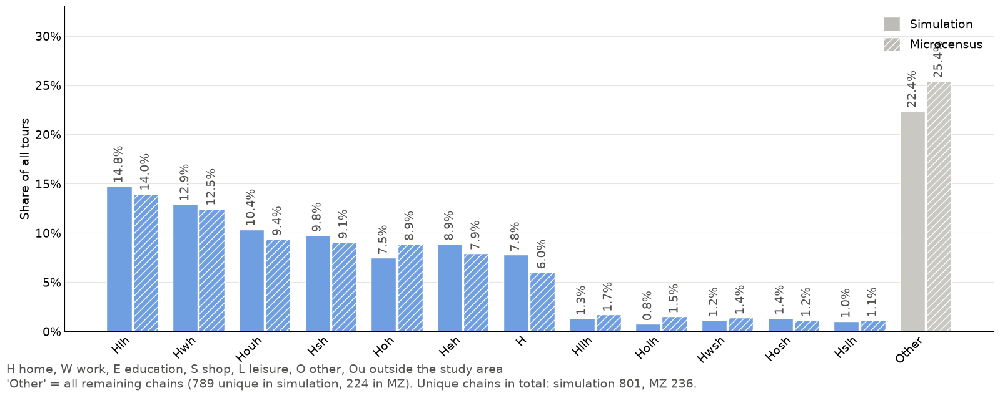

In [25]:
def unique_chain_summary(sim, mz):
    """Number of distinct chains (unweighted) in each source."""
    s, m = set(sim['chain']), set(mz['chain'])
    return {'simulation': len(s), 'microcensus': len(m), 'in both': len(s & m),
            'only simulation': len(s - m), 'only microcensus': len(m - s), 'union': len(s | m)}


uniq = {'all': unique_chain_summary(sim_chains, mz_chains)}
for sex in ['male', 'female']:
    uniq[sex] = unique_chain_summary(sim_chains[sim_chains['sex_'] == sex], mz_chains[mz_chains['sex_'] == sex])
save_table(pd.DataFrame(uniq).T, 'chains_unique_counts.csv')

chains_all = chain_order(sim_chains, mz_chains)
chain_cmp = compare(sim_chains, mz_chains, 'chain', chains_all)
chain_cmp.index.name = 'chain'
chain_cmp.to_csv(OUT_DIR / 'chains_total.csv')

top = chains_all[:TOP_N_CHAINS]                     # same chains / order in all following chain figures
chain_cats = top + [OTHER]
sim_top, mz_top = group_other(sim_chains, top), group_other(mz_chains, top)
chain_cmp_top = compare(sim_top, mz_top, 'chain', chain_cats)
chain_cmp_top.index.name = 'chain'
save_table(chain_cmp_top, 'chains_top_other.csv')

n_other_sim = uniq['all']['simulation'] - len(set(sim_chains['chain']) & set(top))
n_other_mz  = uniq['all']['microcensus'] - len(set(mz_chains['chain']) & set(top))
grouped_bars(sim_vs_mz(shares(sim_top, 'chain', chain_cats), shares(mz_top, 'chain', chain_cats)),
             chain_cats, 'chains_top.png', colors={**{c: COLORS['pt'] for c in top}, OTHER: OTHER_COLOR},
             ylabel='Share of all tours', rotate=45, value_rotation=90,
             note=f"{CHAIN_NOTE}\n'Other' = all remaining chains ({n_other_sim:,} unique in simulation, {n_other_mz:,} in MZ). "
                  f"Unique chains in total: simulation {uniq['all']['simulation']:,}, MZ {uniq['all']['microcensus']:,}.")




--- Male ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1539  0.1457   0.8163   3544   129
HWH    0.1493  0.1362   1.3133   3440   113
HOuH   0.1178  0.1182  -0.0381   2713   103
HSH    0.0812  0.0711   1.0163   1871    60
HOH    0.0639  0.0595   0.4384   1471    54
HEH    0.0930  0.0949  -0.1867   2142    99
H      0.0624  0.0553   0.7091   1438    50
HLLH   0.0146  0.0184  -0.3765    336    18
HOLH   0.0073  0.0128  -0.5445    169    10
HWSH   0.0085  0.0098  -0.1296    196     7
HOSH   0.0091  0.0088   0.0313    209     7
HSLH   0.0107  0.0108  -0.0100    246    11
Other  0.2283  0.2587  -3.0392   5259   222

--- Female ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1414  0.1348   0.6590   3371   154
HWH    0.1095  0.1147  -0.5281   2610   115
HOuH   0.0900  0.0734   1.6594   2146    87
HSH    0.1137  0.1071   0.6598   2710   120
HOH    0.0851  0.1137  -2.8613   2029   125
HE

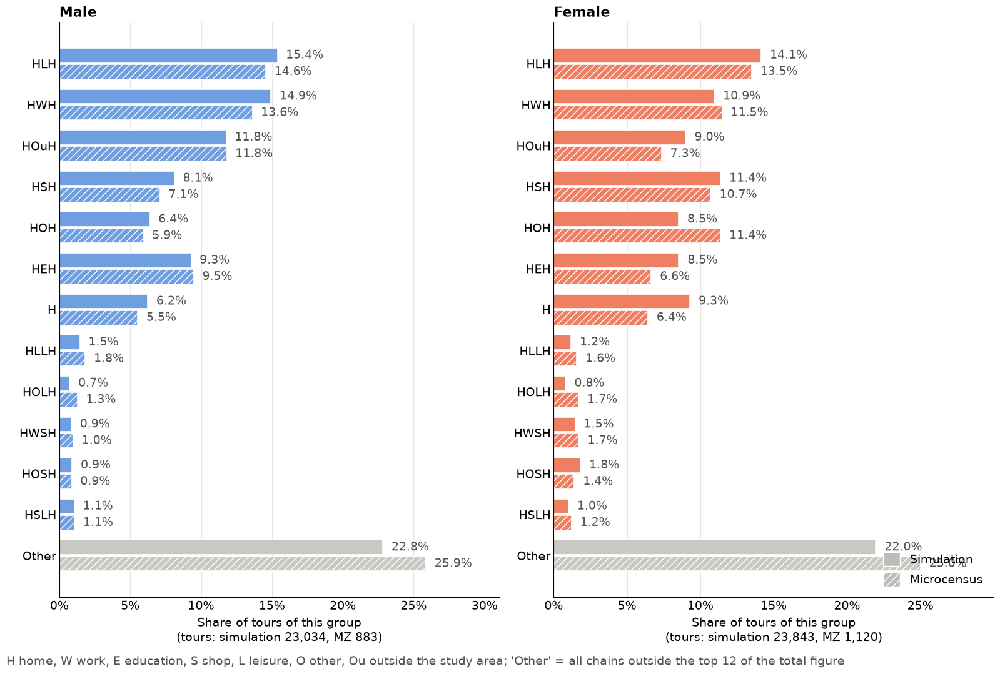


--- Income classes 1–5 (< 10k CHF) ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1527  0.1462   0.6432   4607   147
HWH    0.1226  0.1600  -3.7440   3699   147
HOuH   0.1008  0.0957   0.5104   3043    97
HSH    0.1074  0.1069   0.0481   3242   110
HOH    0.0747  0.1143  -3.9533   2255   118
HEH    0.0823  0.0139   6.8398   2484    15
H      0.0909  0.0670   2.3909   2742    73
HLLH   0.0142  0.0093   0.4918    429    10
HOLH   0.0086  0.0140  -0.5379    261    15
HWSH   0.0109  0.0138  -0.2877    329    15
HOSH   0.0130  0.0150  -0.1942    393    14
HSLH   0.0105  0.0104   0.0095    316    10
Other  0.2113  0.2335  -2.2164   6378   224

--- Income classes 6–9 (> 10k CHF) ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1382  0.1080   3.0166   2308    44
HWH    0.1408  0.1111   2.9729   2351    47
HOuH   0.1087  0.1236  -1.4843   1816    50
HSH    0.0802  0.0478   3.2362   1339   

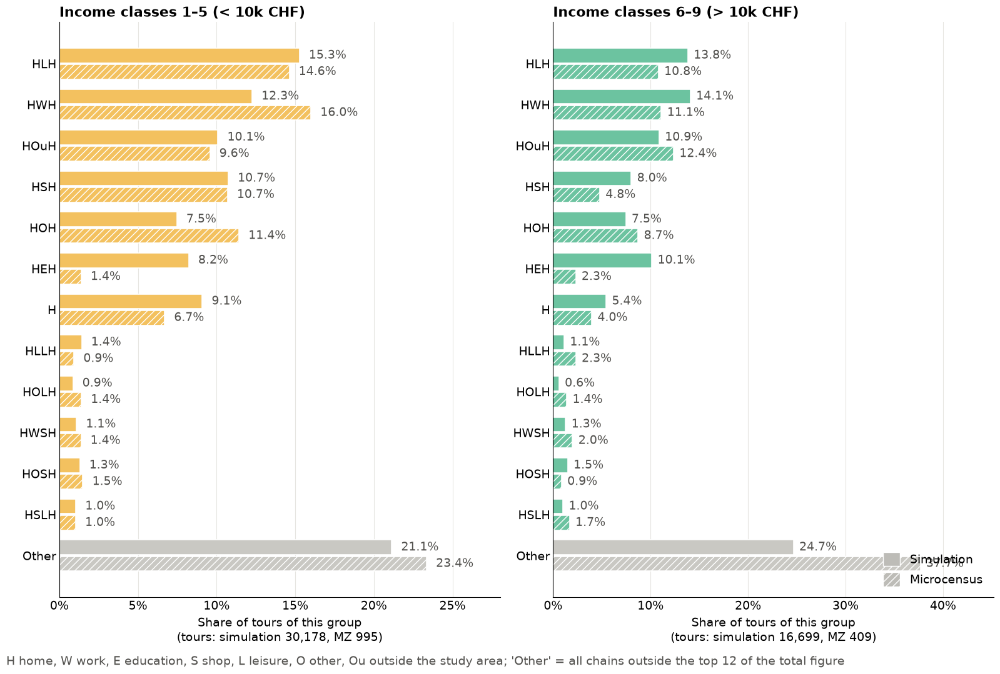


--- With driving licence (all ages 6+) ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1421  0.1380   0.4024   4685   186
HWH    0.1621  0.1512   1.0921   5345   193
HOuH   0.1185  0.1124   0.6072   3907   155
HSH    0.0997  0.0841   1.5624   3289   116
HOH    0.0875  0.1018  -1.4288   2886   143
HEH    0.0178  0.0141   0.3692    586    19
H      0.0681  0.0506   1.7522   2246    73
HLLH   0.0135  0.0139  -0.0363    446    21
HOLH   0.0075  0.0145  -0.6964    247    19
HWSH   0.0148  0.0140   0.0739    487    18
HOSH   0.0150  0.0134   0.1590    495    17
HSLH   0.0109  0.0099   0.0948    358    15
Other  0.2426  0.2822  -3.9516   8002   368

--- Without driving licence (all ages 6+) ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1605  0.1434   1.7094   2230    97
HWH    0.0507  0.0693  -1.8584    705    35
HOuH   0.0685  0.0553   1.3207    952    35
HSH    0.0930  0.1042  -1.123

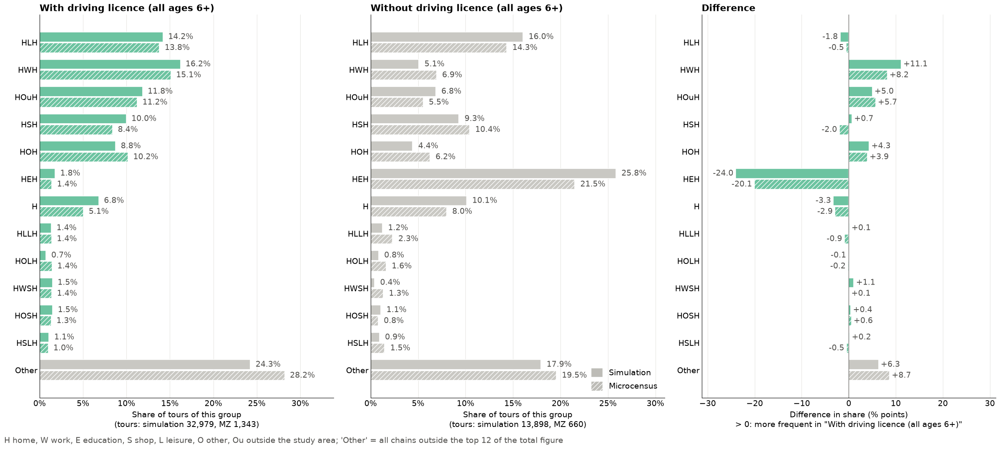


--- With driving licence (age 18+) ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1421  0.1380   0.4024   4685   186
HWH    0.1621  0.1512   1.0921   5345   193
HOuH   0.1185  0.1124   0.6072   3907   155
HSH    0.0997  0.0841   1.5624   3289   116
HOH    0.0875  0.1018  -1.4288   2886   143
HEH    0.0178  0.0141   0.3692    586    19
H      0.0681  0.0506   1.7522   2246    73
HLLH   0.0135  0.0139  -0.0363    446    21
HOLH   0.0075  0.0145  -0.6964    247    19
HWSH   0.0148  0.0140   0.0739    487    18
HOSH   0.0150  0.0134   0.1590    495    17
HSLH   0.0109  0.0099   0.0948    358    15
Other  0.2426  0.2822  -3.9516   8002   368

--- Without driving licence (age 18+) ---
          sim      mz  diff_pp  n_sim  n_mz
chain                                      
HLH    0.1438  0.1328   1.0932    998    40
HWH    0.0883  0.1230  -3.4683    613    33
HOuH   0.0897  0.0669   2.2869    623    19
HSH    0.1528  0.1538  -0.0998   1061

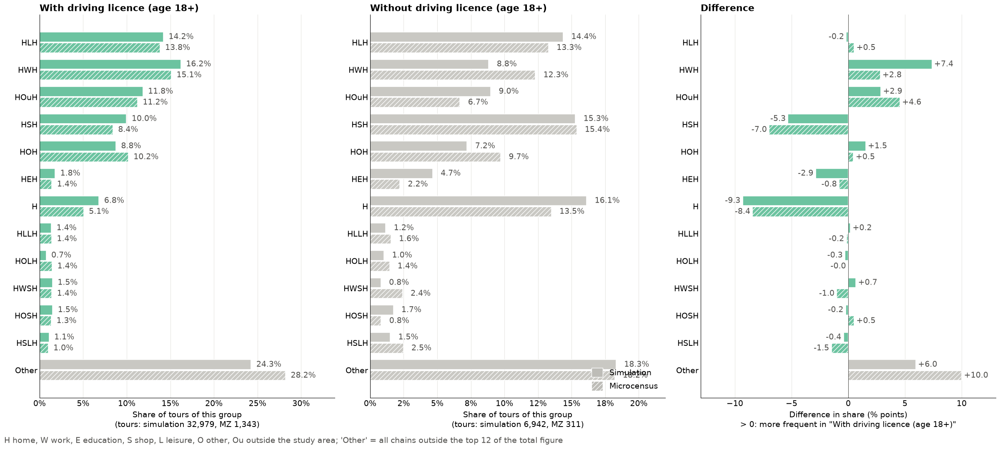

In [26]:
def plot_chain_panels(groups, fname, diff_panel=False):
    """One horizontal-bar panel per group (same chains and order as the total figure).
    groups = list of (key, title, colour, simulation tours, MZ tours).
    diff_panel: add a panel with the difference between the first two groups (% points)."""
    n = len(groups) + diff_panel
    fig, axes = plt.subplots(1, n, figsize=(8 * n, 0.65 * len(chain_cats) + 2.2))
    axes = np.atleast_1d(axes)
    sh = []
    for ax, (key, title, color, sim_g, mz_g) in zip(axes, groups):
        sim_g, mz_g = group_other(sim_g, top), group_other(mz_g, top)
        s, m = shares(sim_g, 'chain', chain_cats), shares(mz_g, 'chain', chain_cats)
        sh.append((s, m))
        res = compare(sim_g, mz_g, 'chain', chain_cats)
        res.index.name = 'chain'
        print(f'\n--- {title} ---'); save_table(res, f'{Path(fname).stem}_{key}.csv')
        draw_hbars(ax, s, m, chain_cats, {c: c for c in chain_cats},
                   {**{c: color for c in top}, OTHER: OTHER_COLOR})
        ax.set_title(title)
        ax.set_xlabel(f'Share of tours of this group\n(tours: simulation {len(sim_g):,}, MZ {len(mz_g):,})')
    axes[min(1, len(groups) - 1)].legend(handles=src_legend(), frameon=False, loc='lower right',
                                         handlelength=1.4, handleheight=1.4)
    if diff_panel:                                   # first group minus second group, per source
        ax = axes[-1]
        dif = pd.DataFrame({'sim_diff_pp': (sh[0][0] - sh[1][0]) * 100, 'mz_diff_pp': (sh[0][1] - sh[1][1]) * 100})
        dif.index.name = 'chain'
        dif.round(4).to_csv(OUT_DIR / f'{Path(fname).stem}_difference.csv')
        y = np.arange(len(chain_cats))[::-1]
        lim = max(dif.abs().max().max(), 0.5)
        for offset, col, hatch in [(+(BAR_H + BAR_GAP) / 2, 'sim_diff_pp', None), (-(BAR_H + BAR_GAP) / 2, 'mz_diff_pp', HATCH_MZ)]:
            v = dif[col].reindex(chain_cats)
            ax.barh(y + offset, v, BAR_H, hatch=hatch, edgecolor='white', linewidth=1.2,
                    color=[groups[0][2] if c in top else OTHER_COLOR for c in chain_cats])
            for yi, val in zip(y + offset, v):
                ax.text(val + (0.02 if val >= 0 else -0.02) * lim, yi, f'{val:+.1f}', va='center',
                        ha='left' if val >= 0 else 'right', fontsize=FS['value'], color=TEXT_COLOR)
        ax.axvline(0, color=TEXT_COLOR, linewidth=0.8)
        ax.set_yticks(y, chain_cats)
        ax.set_xlim(-lim * 1.3, lim * 1.3)
        ax.set_xlabel(f'Difference in share (% points)\n> 0: more frequent in "{groups[0][1]}"')
        ax.set_title('Difference')
        style_axes(ax, 'x')
    finish(fig, fname, note=f"{CHAIN_NOTE}; 'Other' = all chains outside the top {TOP_N_CHAINS} of the total figure",
           note_y=-0.01)


# --- by sex ---
plot_chain_panels([(sex, nice_label(sex), SEX_COLORS[sex],
                    sim_chains[sim_chains['sex_'] == sex], mz_chains[mz_chains['sex_'] == sex])
                   for sex in ['male', 'female']], 'chains_by_sex.png')

# --- by income group (simulation: household income, MZ: household income F20601A) ---
plot_chain_panels([(f'income_{"_".join(map(str, cl))}', label, INCOME_GROUP_COLORS[label],
                    sim_chains[sim_chains['income'].isin(cl)], mz_chains[mz_chains['income'].isin(cl)])
                   for label, cl in INCOME_GROUPS.items()], 'chains_by_income.png')


# --- by driving licence (all ages, and 18+ so that children do not dominate "no licence") ---
def chains_by_licence(min_age, fname, tag):
    groups = []
    for lic, name in [('yes', 'With driving licence'), ('no', 'Without driving licence')]:
        sel_s, sel_m = sim_chains['licence'] == lic, mz_chains['licence'] == lic
        if min_age is not None:
            sel_s &= sim_chains['age'] >= min_age
            sel_m &= mz_chains['age'] >= min_age
        groups.append((lic, f'{name} {tag}', LICENCE_COLORS[lic], sim_chains[sel_s], mz_chains[sel_m]))
    plot_chain_panels(groups, fname, diff_panel=True)


chains_by_licence(None, 'chains_by_licence.png', f'(all ages {MIN_AGE}+)')
chains_by_licence(18, 'chains_by_licence_18plus.png', '(age 18+)')


 ## Destination maps

 Weekday destinations (work, education, shopping, leisure) inside the study area. Each cell shows the % of the

 purpose's destinations falling into it, so simulation and Microcensus are comparable despite different sizes.

In [27]:
# simulation: all such activities of agents aged MIN_AGE+
sim_d = sim_acts.merge(sim_p[['person', 'age', 'car']], on='person')
sim_d['purpose'] = sim_d['type'].map(MATSIM_MAP)
sim_d = sim_d[sim_d['purpose'].isin(MAP_PURPOSES) & inside(sim_d['x'], sim_d['y'])]
sim_d = sim_d.assign(w=1.0)[['purpose', 'x', 'y', 'w', 'age', 'car']]

# Microcensus: weekday trips ending inside the study area
mz_d = mz_t[mz_t['letter'].isin(MAP_PURPOSES) & mz_t['dest_in']]
mz_d = mz_d.rename(columns={'letter': 'purpose', 'dx': 'x', 'dy': 'y', 'weight': 'w'})[
    ['purpose', 'x', 'y', 'w', 'age', 'car']]
print(f'Destinations inside the area: simulation {len(sim_d):,}, MZ {len(mz_d):,} (unweighted)')

print('\nSimulation, carAvail x licence (persons):')
print(pd.crosstab(sim_p['car'].fillna('<missing>'), sim_p['licence'].fillna('<missing>')))
print('\nMZ weekday trips by car availability:')
print(mz_t['car'].fillna('other / sometimes').value_counts().to_string())



Destinations inside the area: simulation 51,916, MZ 3,965 (unweighted)

Simulation, carAvail x licence (persons):
licence    no    yes
car                 
always      0  20710
never    9714   2342

MZ weekday trips by car availability:
car
always               2778
never                1863
other / sometimes     719


In [28]:
def hex_cells(x, y, size, x0, y0):
    """Points -> axial coordinates (q, r) of a pointy-top hexagonal grid. size = centre-to-corner [m]."""
    x, y = np.asarray(x, float) - x0, np.asarray(y, float) - y0
    q = (np.sqrt(3) / 3 * x - y / 3) / size
    r = (2 / 3 * y) / size
    cx, cz = q, r                                    # cube rounding
    cy = -cx - cz
    rx, ry, rz = np.round(cx), np.round(cy), np.round(cz)
    dx, dy, dz = np.abs(rx - cx), np.abs(ry - cy), np.abs(rz - cz)
    m1 = (dx > dy) & (dx > dz)
    m2 = ~m1 & (dy > dz)
    return np.where(m1, -ry - rz, rx).astype(int), np.where(~m1 & ~m2, -rx - ry, rz).astype(int)


def hex_polygons(values, cell_m, cmap, norm, alpha):
    """PolyCollection with one hexagon per (q, r) index of the Series `values` (cell_m = hexagon width)."""
    minx, miny = area.total_bounds[:2]
    size = cell_m / np.sqrt(3)
    angles = np.deg2rad(30 + 60 * np.arange(6))
    corners = size * np.column_stack([np.cos(angles), np.sin(angles)])
    q, r = values.index.get_level_values(0).to_numpy(), values.index.get_level_values(1).to_numpy()
    cx, cy = size * np.sqrt(3) * (q + r / 2) + minx, size * 1.5 * r + miny
    verts = np.stack([cx, cy], axis=1)[:, None, :] + corners[None, :, :]
    pc = PolyCollection(verts, array=values.to_numpy(), cmap=cmap, alpha=alpha, edgecolors='white', linewidths=0.2)
    pc.set_norm(norm)
    return pc


def hex_shares(d, cell_m):
    """% of the destinations in `d` (columns x, y, w) per hexagon; empty Series if no destinations."""
    if len(d) == 0:
        return pd.Series(dtype=float, index=pd.MultiIndex.from_arrays([[], []]))
    minx, miny = area.total_bounds[:2]
    q, r = hex_cells(d['x'], d['y'], cell_m / np.sqrt(3), minx, miny)
    s = d['w'].groupby([q, r]).sum()
    return 100 * s / s.sum()


def rel_diff(sim_g, mz_g):
    """Relative difference (Sim - MZ) / MZ in %, only for hexagons with >= MIN_MZ_SHARE % of the MZ destinations."""
    mz_g = mz_g[mz_g >= MIN_MZ_SHARE]
    return 100 * (sim_g.reindex(mz_g.index, fill_value=0) - mz_g) / mz_g


def rel_norm_from(diffs):
    """Colour scale of relative differences: -100 % ... largest positive value, centred on 0."""
    lim = max((d.max() for d in diffs if len(d)), default=100.0)
    return TwoSlopeNorm(vcenter=0, vmin=-100, vmax=max(lim, 1e-6))


def decorate(ax, extra_boundaries=None):
    """Study-area outline + swisstopo background, no ticks."""
    if extra_boundaries is not None:
        extra_boundaries.boundary.plot(ax=ax, color='#8a8984', linewidth=0.4)
    area.boundary.plot(ax=ax, color='black', linewidth=1)
    minx, miny, maxx, maxy = area.total_bounds
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
    try:                                             # tiles need internet access
        ctx.add_basemap(ax, source=SWISSTOPO_TILES, crs=area.crs, zoom=MAP_ZOOM, attribution=False)
    except Exception as e:
        print('basemap not available:', type(e).__name__)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])


def select_age(df, age_range):
    lo, hi = age_range
    keep = np.ones(len(df), dtype=bool)
    if lo is not None: keep &= (df['age'] >= lo).to_numpy()
    if hi is not None: keep &= (df['age'] <= hi).to_numpy()
    return df[keep]


def colourbar(fig, mappable, axes, label):
    cb = fig.colorbar(mappable, ax=axes, location='right', shrink=0.8, pad=0.01, label=label)
    cb.ax.tick_params(labelsize=FS['text'])


def finish_map(fig, fname, title):
    fig.suptitle(title)
    fig.text(0.995, 0.005, 'Background: \u00a9 swisstopo', ha='right', fontsize=FS['note'])
    fig.savefig(OUT_DIR / fname, dpi=DPI)
    plt.show()



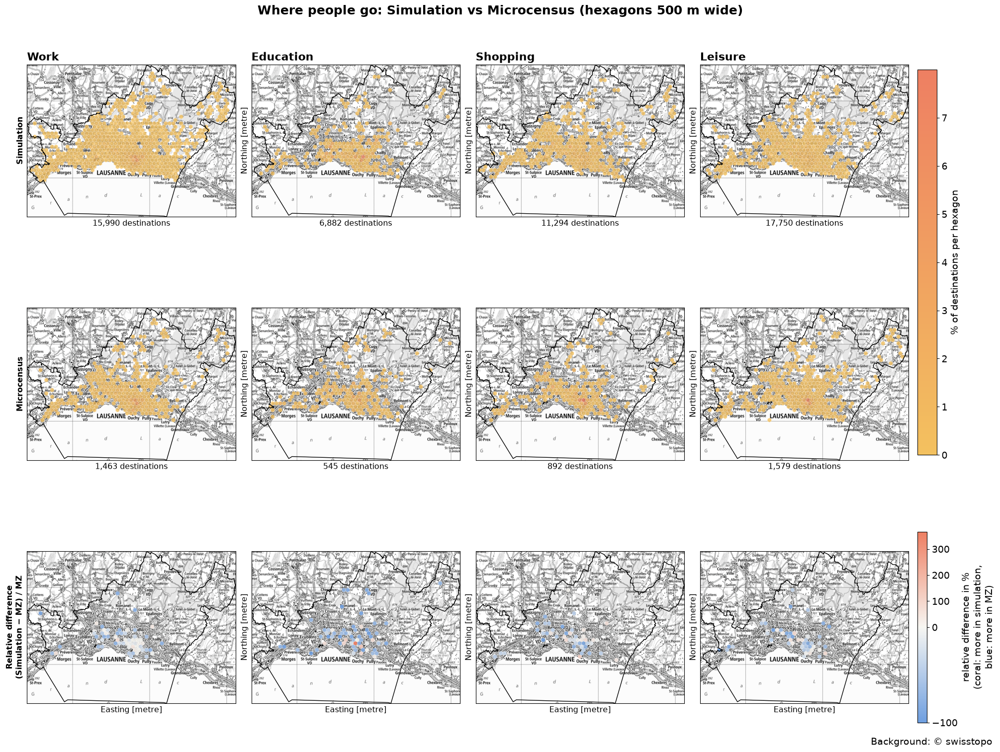

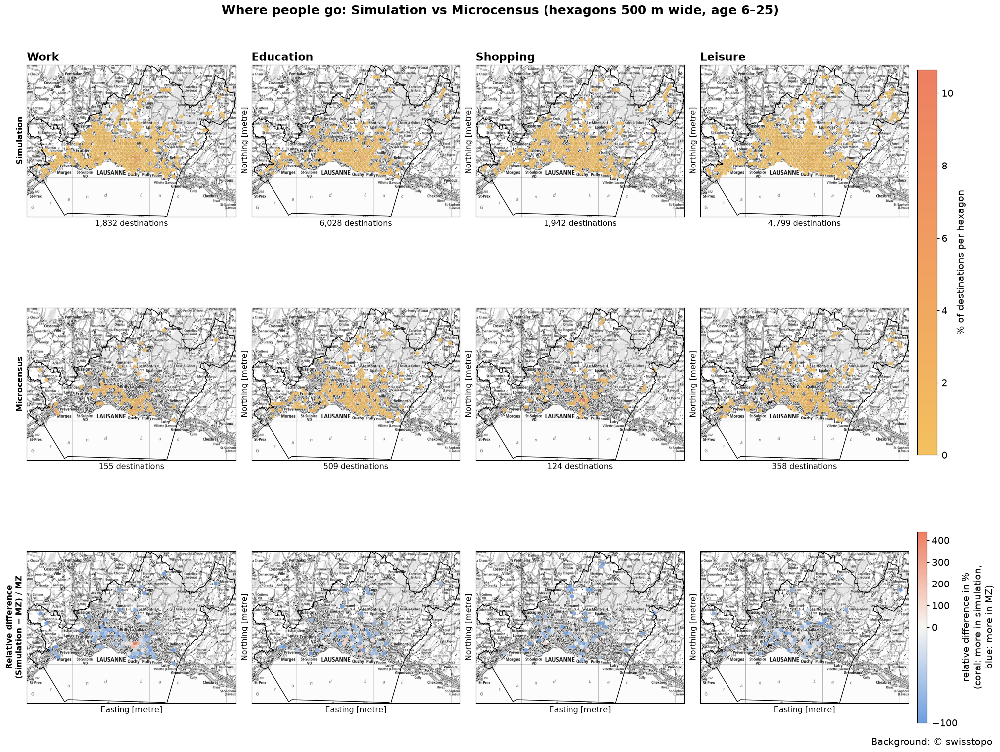

In [29]:
def plot_destination_maps(sim_d, mz_d, cell_m, age_range, fname):
    sources = {'Simulation': select_age(sim_d, age_range), 'Microcensus': select_age(mz_d, age_range)}

    # % of the purpose's destinations per hexagon, and relative difference Sim vs MZ
    grids, totals, diffs = {}, {}, {}
    for code in MAP_PURPOSES:
        for src, df in sources.items():
            d = df[df['purpose'] == code]
            totals[code, src] = d['w'].sum()
            grids[code, src] = hex_shares(d, cell_m)
        diffs[code] = rel_diff(grids[code, 'Simulation'], grids[code, 'Microcensus'])

    seq_norm = Normalize(0, max((g.max() for g in grids.values() if len(g)), default=1.0))
    div_norm = rel_norm_from(diffs.values())

    fig, axes = plt.subplots(3, len(MAP_PURPOSES), figsize=(20, 15), layout='constrained')
    for j, (code, name) in enumerate(MAP_PURPOSES.items()):
        for i, src in enumerate(sources):
            ax = axes[i, j]
            ax.add_collection(hex_polygons(grids[code, src], cell_m, SEQ_CMAP, seq_norm, 0.8))
            decorate(ax)
            ax.set_xlabel(f'{totals[code, src]:,.0f} destinations')
            if i == 0: ax.set_title(name, fontsize=FS['title'])
            if j == 0: ax.set_ylabel(src, fontweight='bold')
        ax = axes[2, j]
        ax.add_collection(hex_polygons(diffs[code], cell_m, DIV_CMAP, div_norm, 0.9))
        decorate(ax)
        if j == 0: ax.set_ylabel('Relative difference\n(Simulation − MZ) / MZ', fontweight='bold')

    colourbar(fig, ScalarMappable(seq_norm, SEQ_CMAP), axes[:2, :], '% of destinations per hexagon')
    colourbar(fig, ScalarMappable(div_norm, DIV_CMAP), axes[2, :],
              'relative difference in %\n(coral: more in simulation,\nblue: more in MZ)')
    lo, hi = age_range
    age_label = f', age {lo}–{hi}' if lo is not None or hi is not None else ''
    finish_map(fig, fname, f'Where people go: Simulation vs Microcensus (hexagons {cell_m} m wide{age_label})')


for run in MAP_RUNS:
    lo, hi = run['age_range']
    tag = 'all_ages' if lo is None and hi is None else f'age{lo}-{hi}'
    plot_destination_maps(sim_d, mz_d, run['cell_m'], run['age_range'],
                          f'destination_maps_hex_{tag}_{run["cell_m"]}m.png')


Car always available, destinations in the area: simulation 33,764, MZ 1,924


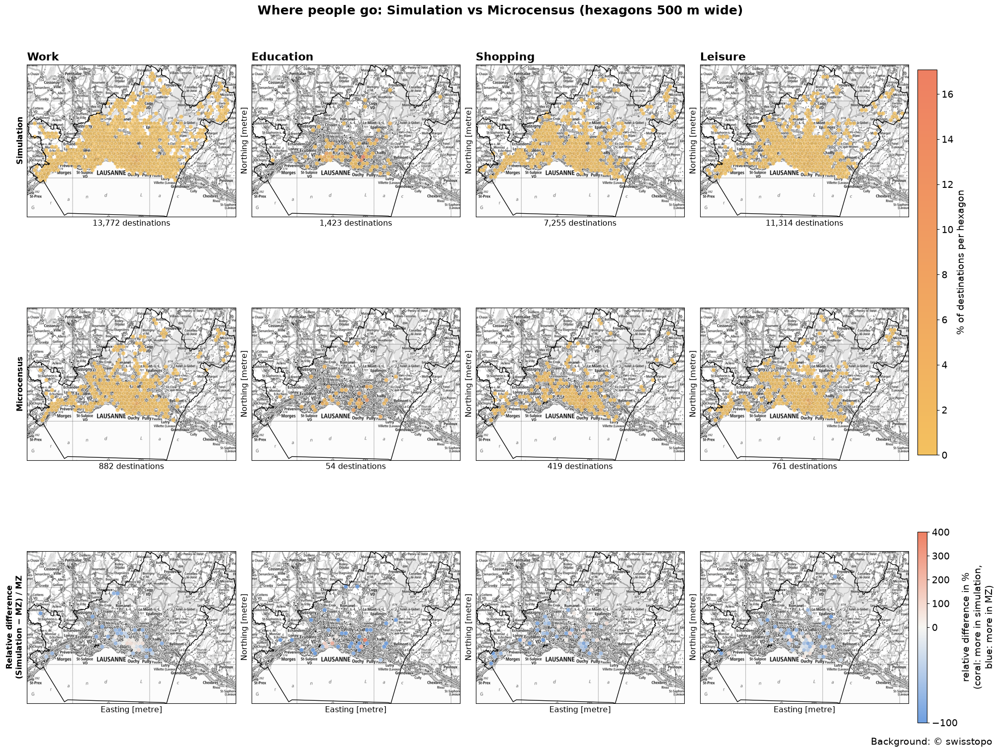

In [30]:
sim_always, mz_always = sim_d[sim_d['car'] == 'always'], mz_d[mz_d['car'] == 'always']
print(f'Car always available, destinations in the area: simulation {len(sim_always):,}, MZ {len(mz_always):,}')
plot_destination_maps(sim_always, mz_always, 500, (None, None), 'destination_maps_car_always_500m.png')


64 municipalities touch the study area
Destinations assigned to a municipality: simulation 51,916, MZ 3,965 (unweighted)


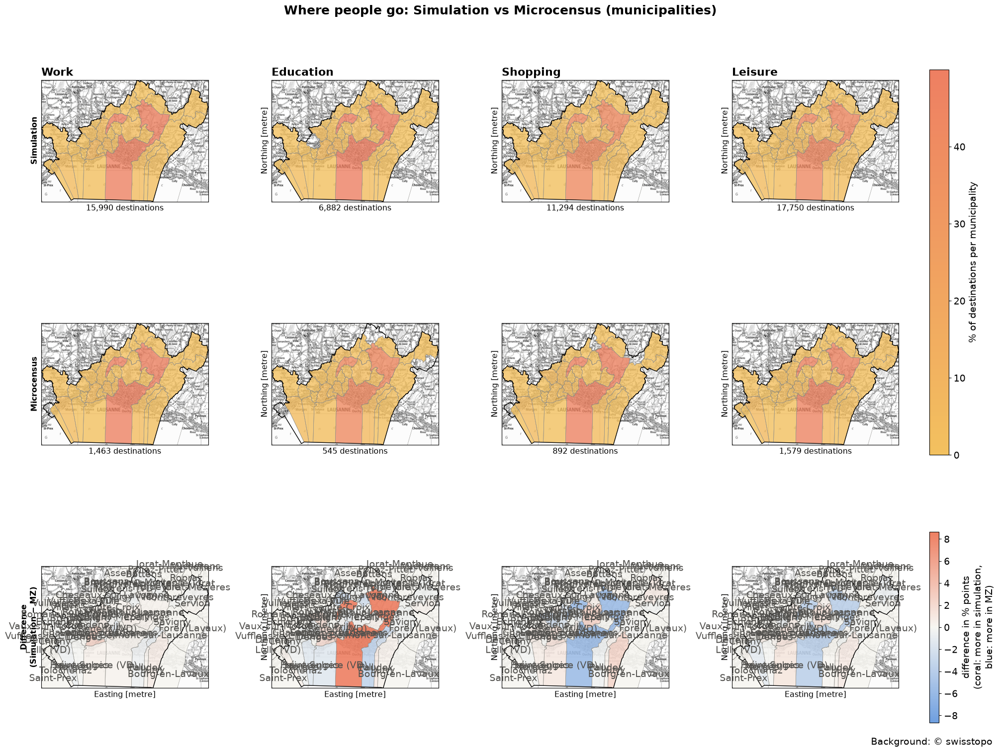

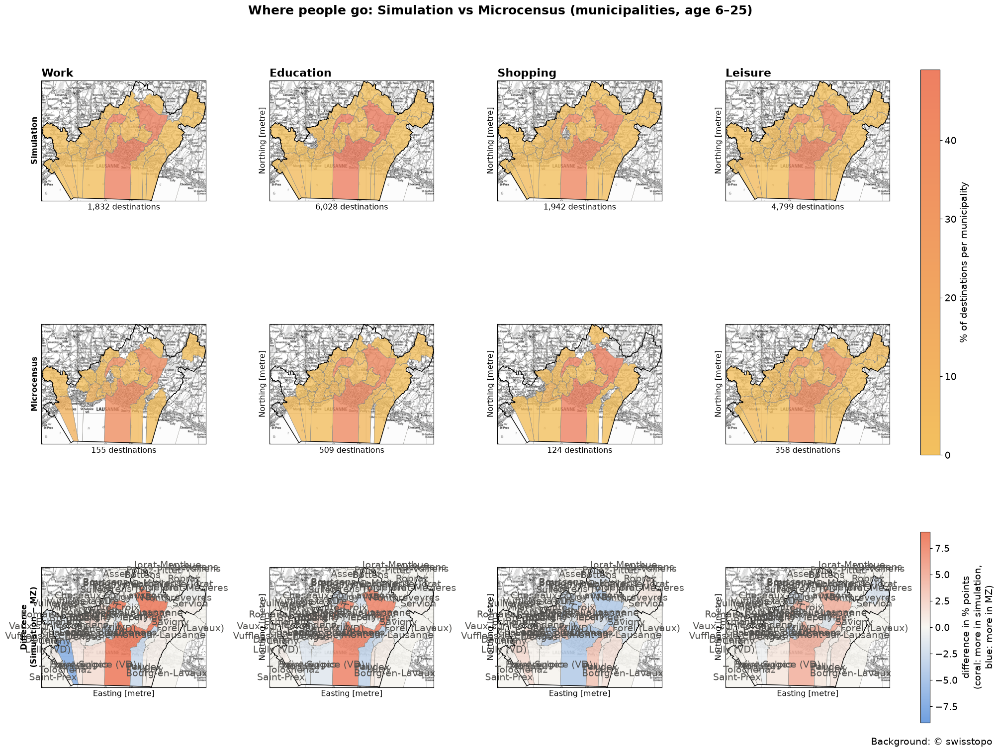

In [31]:
munis = munis_all[munis_all.intersects(shape)].reset_index(drop=True)
munis['mid'] = munis.index
munis['area_km2'] = munis.geometry.area / 1e6
print(f'{len(munis)} municipalities touch the study area')


def assign_muni(df):
    """Add 'mid' = index of the municipality containing each destination (destinations outside are dropped)."""
    df = df.reset_index(drop=True)
    pts = gpd.GeoDataFrame(df[['x']].copy(), geometry=gpd.points_from_xy(df['x'], df['y']), crs=2056)
    j = gpd.sjoin(pts, munis[['mid', 'geometry']], how='left', predicate='within')
    j = j[~j.index.duplicated()]
    out = df.assign(mid=j['mid'].reindex(df.index).to_numpy())
    return out.dropna(subset=['mid']).astype({'mid': int})


sim_dm, mz_dm = assign_muni(sim_d), assign_muni(mz_d)
print(f'Destinations assigned to a municipality: simulation {len(sim_dm):,}, MZ {len(mz_dm):,} (unweighted)')


def plot_muni_maps(sim_d, mz_d, age_range, fname):
    sources = {'Simulation': select_age(sim_d, age_range), 'Microcensus': select_age(mz_d, age_range)}
    unit_label = '% of destinations per km²' if VALUE_MODE == 'density' else '% of destinations per municipality'

    # value per municipality, per source and purpose; difference in percentage points
    vals, totals, diffs = {}, {}, {}
    for code in MAP_PURPOSES:
        for src, df in sources.items():
            d = df[df['purpose'] == code]
            totals[code, src] = d['w'].sum()
            s = d.groupby('mid')['w'].sum().reindex(munis['mid']).fillna(0)
            v = 100 * s / s.sum() if s.sum() > 0 else s
            vals[code, src] = v / munis['area_km2'] if VALUE_MODE == 'density' else v
        diffs[code] = vals[code, 'Simulation'] - vals[code, 'Microcensus']

    seq_norm = Normalize(0, max(v.max() for v in vals.values()) or 1.0)
    lim = max(d.abs().max() for d in diffs.values()) or 1.0
    div_norm = Normalize(-lim, lim)

    def draw(ax, v, cmap, norm, alpha):
        g = munis.assign(v=v.to_numpy())
        if cmap is SEQ_CMAP:
            g = g[g['v'] > 0]                        # no destinations -> leave unfilled
        g.plot(column='v', cmap=cmap, norm=norm, ax=ax, alpha=alpha, edgecolor='none')
        decorate(ax, extra_boundaries=munis)

    minx, miny, maxx, maxy = area.total_bounds
    fig, axes = plt.subplots(3, len(MAP_PURPOSES), figsize=(20, 15), layout='constrained')
    for j, (code, name) in enumerate(MAP_PURPOSES.items()):
        for i, src in enumerate(sources):
            ax = axes[i, j]
            draw(ax, vals[code, src], SEQ_CMAP, seq_norm, 0.8)
            ax.set_xlabel(f'{totals[code, src]:,.0f} destinations')
            if i == 0: ax.set_title(name, fontsize=FS['title'])
            if j == 0: ax.set_ylabel(src, fontweight='bold')
        ax = axes[2, j]
        draw(ax, diffs[code], DIV_CMAP, div_norm, 0.9)
        if LABEL_MUNIS:
            for _, mrow in munis.iterrows():
                p = mrow.geometry.representative_point()
                if minx <= p.x <= maxx and miny <= p.y <= maxy:
                    ax.annotate(str(mrow[NAME_COL]), (p.x, p.y), ha='center', fontsize=FS['map_label'], color=TEXT_COLOR)
        if j == 0: ax.set_ylabel('Difference\n(Simulation − MZ)', fontweight='bold')

    colourbar(fig, ScalarMappable(seq_norm, SEQ_CMAP), axes[:2, :], unit_label)
    colourbar(fig, ScalarMappable(div_norm, DIV_CMAP), axes[2, :],
              'difference in % points' + (' per km²' if VALUE_MODE == 'density' else '')
              + '\n(coral: more in simulation,\nblue: more in MZ)')
    lo, hi = age_range
    age_label = f', age {lo}–{hi}' if lo is not None or hi is not None else ''
    finish_map(fig, fname, f'Where people go: Simulation vs Microcensus (municipalities{age_label})')

    # table with the numbers behind the maps
    pd.concat([pd.DataFrame({'purpose': code, 'municipality': munis[NAME_COL], 'sim': vals[code, 'Simulation'],
                             'mz': vals[code, 'Microcensus'], 'diff': diffs[code]}) for code in MAP_PURPOSES]
              ).round(3).to_csv(OUT_DIR / fname.replace('.png', '.csv'), index=False)


for run in MAP_RUNS:
    lo, hi = run['age_range']
    tag = 'all_ages' if lo is None and hi is None else f'age{lo}-{hi}'
    plot_muni_maps(sim_dm, mz_dm, run['age_range'], f'destination_maps_muni_{VALUE_MODE}_{tag}.png')


 ## Shopping destinations: car available vs no car

 Columns 1-2: car always available / no car (persons without licence count as "no car"; "sometimes" is left out).

 Row 3: relative difference Simulation vs MZ. Column 3: impact of car ownership within one source

 (share with car − share without car, % points).

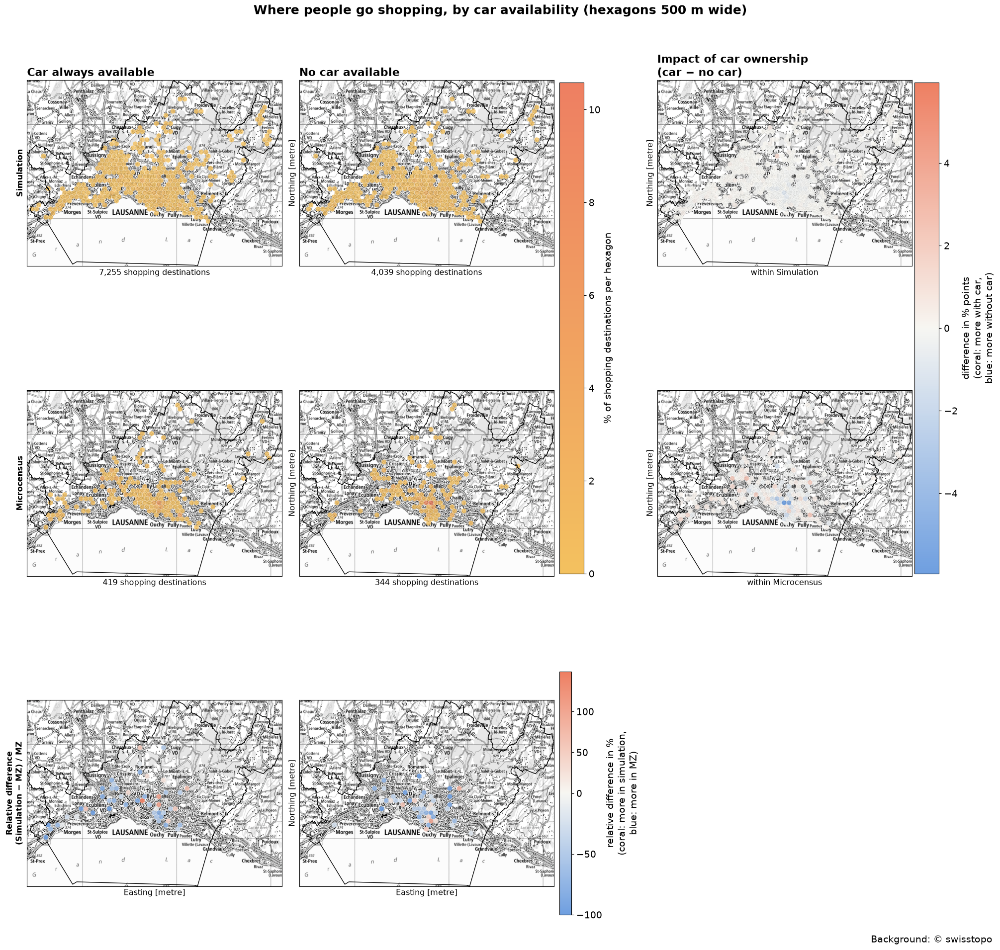

In [32]:
def plot_shopping_car_maps(sim_d, mz_d, cell_m, fname, purpose='S'):
    sources = {'Simulation': sim_d, 'Microcensus': mz_d}

    # % of the group's shopping destinations per hexagon
    grids, totals = {}, {}
    for src, df in sources.items():
        for g in CAR_GROUPS:
            d = df[(df['purpose'] == purpose) & (df['car'] == g)]
            totals[src, g] = d['w'].sum()
            grids[src, g] = hex_shares(d, cell_m)

    # Simulation vs MZ per car group (relative difference)
    diff_src = {g: rel_diff(grids['Simulation', g], grids['Microcensus', g]) for g in CAR_GROUPS}

    # impact of car ownership within one source (% points, car - no car)
    diff_car = {}
    for src in sources:
        a, b = grids[src, 'always'], grids[src, 'never']
        idx = a.index.union(b.index)
        diff_car[src] = a.reindex(idx, fill_value=0) - b.reindex(idx, fill_value=0)

    seq_norm = Normalize(0, max((g.max() for g in grids.values() if len(g)), default=1.0))
    rel_norm = rel_norm_from(diff_src.values())
    lim_car = max((d.abs().max() for d in diff_car.values() if len(d)), default=1.0)
    car_norm = Normalize(-max(lim_car, 1e-6), max(lim_car, 1e-6))

    fig, axes = plt.subplots(3, 3, figsize=(20, 19), layout='constrained')
    for i, src in enumerate(sources):
        for j, g in enumerate(CAR_GROUPS):
            ax = axes[i, j]
            ax.add_collection(hex_polygons(grids[src, g], cell_m, SEQ_CMAP, seq_norm, 0.8))
            decorate(ax)
            ax.set_xlabel(f'{totals[src, g]:,.0f} shopping destinations')
            if i == 0: ax.set_title(CAR_GROUPS[g], fontsize=FS['title'])
            if j == 0: ax.set_ylabel(src, fontweight='bold')
        ax = axes[i, 2]                              # impact of car within this source
        ax.add_collection(hex_polygons(diff_car[src], cell_m, DIV_CMAP, car_norm, 0.9))
        decorate(ax)
        if i == 0: ax.set_title('Impact of car ownership\n(car − no car)', fontsize=FS['title'])
        ax.set_xlabel(f'within {src}')

    for j, g in enumerate(CAR_GROUPS):               # row 3: Simulation vs MZ
        ax = axes[2, j]
        ax.add_collection(hex_polygons(diff_src[g], cell_m, DIV_CMAP, rel_norm, 0.9))
        decorate(ax)
        if j == 0: ax.set_ylabel('Relative difference\n(Simulation − MZ) / MZ', fontweight='bold')
    axes[2, 2].axis('off')

    colourbar(fig, ScalarMappable(seq_norm, SEQ_CMAP), axes[:2, :2], '% of shopping destinations per hexagon')
    colourbar(fig, ScalarMappable(rel_norm, DIV_CMAP), axes[2, :2],
              'relative difference in %\n(coral: more in simulation,\nblue: more in MZ)')
    colourbar(fig, ScalarMappable(car_norm, DIV_CMAP), axes[:2, 2],
              'difference in % points\n(coral: more with car,\nblue: more without car)')
    finish_map(fig, fname, f'Where people go shopping, by car availability (hexagons {cell_m} m wide)')


plot_shopping_car_maps(sim_d, mz_d, cell_m=500, fname='destination_maps_shopping_car_500m.png')